Exploratory Data Analysis (EDA) Case Study — opt.csv
Google Colab / Python notebook

This notebook follows the broad structure of the reference case study: dataset overview, data quality, univariate and bivariate analysis, multivariate visualization, correlations, outlier checks, statistical tests, feature engineering, PCA, clustering, and (when the data supports it) predictive modelling.

Dataset: https://raw.githubusercontent.com/salemprakash/EDA/main/Data/opt.csv

The code detects numeric and categorical columns automatically, so it can work even when the exact column names differ from the reference dataset. Read the printed outputs and write your own interpretations from the actual results.

1. Import libraries and set plotting style

In [ ]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats
from scipy.stats import chi2_contingency, mannwhitneyu, kruskal, pearsonr, spearmanr

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["figure.dpi"] = 110

print("Libraries imported successfully.")

Libraries imported successfully.


2. Load the dataset and inspect the first records

In [ ]:
DATA_URL = "https://raw.githubusercontent.com/salemprakash/EDA/main/Data/opt.csv"
df_raw = pd.read_csv(DATA_URL)
df = df_raw.copy()

print("Dataset shape:", df.shape)
print("\nFirst 10 records:")
display(df.head(10))
print("\nLast 5 records:")
display(df.tail())
print("\nRandom sample:")
display(df.sample(min(5, len(df)), random_state=42))

Dataset shape: (823, 172)

First 10 records:


,rownames,PID,Clinic,Group,Age,Black,White,Nat.Am,Asian,Hisp,...,BL..FN,BL..S7,V5..AA,V5..PG,V5..TD,V5..TF,V5..PI,V5..CR,V5..FN,V5..S7
0,1,100034,NY,C,25,Yes,No,No,No,,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2,100042,NY,C,21,Yes,No,No,No,,...,22.15,33.02,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,3,100067,NY,T,25,No,Yes,No,No,Yes,...,12.51,23.31,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,4,100083,NY,C,36,Yes,No,No,No,,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,5,100091,NY,C,21,No,Yes,No,No,Yes,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,6,100109,NY,T,40,No,No,No,Yes,,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,7,100117,NY,T,23,Yes,No,No,No,,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,8,100133,NY,C,28,Yes,No,No,No,,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,9,100141,NY,T,25,Yes,No,No,No,,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,10,100158,NY,T,27,Yes,No,No,No,,...,19.68,20.86,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN



Last 5 records:


,rownames,PID,Clinic,Group,Age,Black,White,Nat.Am,Asian,Hisp,...,BL..FN,BL..S7,V5..AA,V5..PG,V5..TD,V5..TF,V5..PI,V5..CR,V5..FN,V5..S7
818,819,402428,MS,T,22,Yes,No,No,No,No,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
819,820,402436,MS,C,23,Yes,No,No,No,No,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
820,821,402451,MS,C,29,Yes,No,No,No,No,...,22.52,31.31,0.0,0.0,2.37,1.96,0.0,0.79,22.2,27.31
821,822,402469,MS,T,20,Yes,No,No,No,No,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
822,823,402477,MS,C,24,Yes,No,No,No,No,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN



Random sample:


,rownames,PID,Clinic,Group,Age,Black,White,Nat.Am,Asian,Hisp,...,BL..FN,BL..S7,V5..AA,V5..PG,V5..TD,V5..TF,V5..PI,V5..CR,V5..FN,V5..S7
610,611,302139,KY,C,22,No,Yes,No,No,No,...,NaN,NaN,0.0,4.58,1.19,1.86,2.22,0.49,22.32,32.66
174,175,200067,MN,T,19,No,Yes,Yes,No,,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
67,68,100810,NY,T,21,Yes,No,No,No,No,...,52.89,55.48,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
168,169,101842,NY,C,20,Yes,No,No,No,No,...,20.90,20.92,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
275,276,201289,MN,T,29,Yes,No,No,No,No,...,17.69,47.71,0.0,0.08,0.08,2.03,0.04,2.29,10.91,15.42


3. Dataset structure, column names, and summary statistics


In [ ]:
print("Column names:")
print(df.columns.tolist())

print("\nData types and non-null counts:")
df.info()

print("\nNumeric summary:")
display(df.describe().T)

print("\nCategorical summary:")
display(df.describe(include="object").T)

column_audit = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "non_null": df.notna().sum(),
    "missing": df.isna().sum(),
    "missing_percent": (df.isna().mean() * 100).round(2),
    "unique_values": df.nunique(dropna=True)
})
display(column_audit)

Column names:
['rownames', 'PID', 'Clinic', 'Group', 'Age', 'Black', 'White', 'Nat.Am', 'Asian', 'Hisp', 'Education', 'Public.Asstce', 'Hypertension', 'Diabetes', 'BL.Diab.Type', 'BMI', 'Use.Tob', 'BL.Cig.Day', 'Use.Alc', 'BL.Drks.Day', 'Drug.Add', 'Prev.preg', 'N.prev.preg', 'Live.PTB', 'Any.stillbirth', 'Spont.ab', 'Induced.ab', 'Any.live.ptb.sb.sp.ab.in.ab', 'N.living.kids', 'Tx.comp.', 'Local.anes', 'Topical.Anest', 'Tx.time', 'EDC.necessary.', 'Completed.EDC', 'N.extractions', 'N.perm.restorations', 'N.qualifying.teeth', 'BL.GE', 'BL..BOP', 'BL.PD.avg', 'BL..PD.4', 'BL..PD.5', 'BL.CAL.avg', 'BL..CAL.2', 'BL..CAL.3', 'BL.Calc.I', 'BL.Pl.I', 'V3.GE', 'V3..BOP', 'V3.PD.avg', 'V3..PD.4', 'V3..PD.5', 'V3.CAL.avg', 'V3..CAL.2', 'V3..CAL.3', 'V3.Calc.I', 'V3.Pl.I', 'V5.GE', 'V5..BOP', 'V5.PD.avg', 'V5..PD.4', 'V5..PD.5', 'V5.CAL.avg', 'V5..CAL.2', 'V5..CAL.3', 'V5.Calc.I', 'V5.Pl.I', 'N.PAL.sites', 'Birth.outcome', 'Preg.ended...37.wk', 'GA.at.outcome', 'Birthweight', 'Fetal.congenital.a

,count,mean,std,min,25%,50%,75%,max
rownames,823.0,412.000000,237.723930,1.00,206.50,412.00,617.50,823.00
PID,823.0,252541.347509,106737.056578,100034.00,200501.00,202717.00,302208.00,402477.00
Age,823.0,25.978129,5.565973,16.00,22.00,25.00,30.00,44.00
BMI,750.0,27.669333,7.127299,15.00,23.00,26.00,31.00,68.00
BL.Cig.Day,92.0,8.717391,6.271032,1.00,5.00,7.50,10.00,30.00
...,...,...,...,...,...,...,...,...
V5..TF,325.0,2.923292,3.097833,0.00,0.51,2.02,4.13,19.31
V5..PI,325.0,2.767077,5.167062,0.00,0.00,0.07,3.41,40.73
V5..CR,325.0,1.664892,2.270171,0.00,0.41,0.96,1.92,14.64
V5..FN,325.0,16.857508,8.545836,0.00,10.93,15.36,21.53,49.88



Categorical summary:


,count,unique,top,freq
Clinic,823,4,MN,247
Group,823,2,T,413
Black,823,2,No,451
White,823,2,No,588
Nat.Am,823,2,No,573
...,...,...,...,...
OPGE25,823,629,.,188
OTNF5,823,35,1.2,370
OMMP95,823,474,.,188
ETXU_CAT5,823,6,1,376


,dtype,non_null,missing,missing_percent,unique_values
rownames,int64,823,0,0.00,823
PID,int64,823,0,0.00,823
Clinic,object,823,0,0.00,4
Group,object,823,0,0.00,2
Age,int64,823,0,0.00,28
...,...,...,...,...,...
V5..TF,float64,325,498,60.51,234
V5..PI,float64,325,498,60.51,160
V5..CR,float64,325,498,60.51,205
V5..FN,float64,325,498,60.51,306


4. Data cleaning and preprocessing

In [ ]:
# Missing values
missing_table = pd.DataFrame({
    "Missing Count": df.isna().sum(),
    "Missing %": (df.isna().mean() * 100).round(2)
}).sort_values("Missing Count", ascending=False)
display(missing_table)
print("Total missing cells:", int(df.isna().sum().sum()))

rows_with_missing = df[df.isna().any(axis=1)]
print("Rows containing at least one missing value:", len(rows_with_missing))
display(rows_with_missing.head(10))

# Remove columns with more than 70% missing values
drop_missing_cols = missing_table.index[missing_table["Missing %"] > 70].tolist()
print("Columns removed (>70% missing):", drop_missing_cols)
df = df.drop(columns=drop_missing_cols)

# Remove duplicate rows
duplicate_count = int(df.duplicated().sum())
print("Duplicate rows:", duplicate_count)
df = df.drop_duplicates().copy()

# Fill missing numeric values with median and categorical values with mode.
# This keeps the notebook runnable even when the dataset contains missing values.
num_cols = df.select_dtypes(include=np.number).columns.tolist()
cat_cols = df.select_dtypes(include=["object", "category", "bool"]).columns.tolist()

for col in num_cols:
    if df[col].isna().any():
        df[col] = df[col].fillna(df[col].median())

for col in cat_cols:
    if df[col].isna().any():
        mode_values = df[col].mode(dropna=True)
        fill_value = mode_values.iloc[0] if not mode_values.empty else "Unknown"
        df[col] = df[col].fillna(fill_value)

# Standardize whitespace for text columns (without changing case)
for col in cat_cols:
    df[col] = df[col].astype(str).str.strip()

num_cols = df.select_dtypes(include=np.number).columns.tolist()
cat_cols = df.select_dtypes(include=["object", "category", "bool"]).columns.tolist()

print("Shape after cleaning:", df.shape)
print("Missing values remaining:", int(df.isna().sum().sum()))
display(df.head())

,Missing Count,Missing %
BL.Drks.Day,810,98.42
BL.Diab.Type,799,97.08
BL.Cig.Day,731,88.82
V5.FN,498,60.51
V5.AA,498,60.51
...,...,...
OPI1,0,0.00
OAA5,0,0.00
OCR5,0,0.00
OFN5,0,0.00


Total missing cells: 28285
Rows containing at least one missing value: 823


,rownames,PID,Clinic,Group,Age,Black,White,Nat.Am,Asian,Hisp,...,BL..FN,BL..S7,V5..AA,V5..PG,V5..TD,V5..TF,V5..PI,V5..CR,V5..FN,V5..S7
0,1,100034,NY,C,25,Yes,No,No,No,,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2,100042,NY,C,21,Yes,No,No,No,,...,22.15,33.02,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,3,100067,NY,T,25,No,Yes,No,No,Yes,...,12.51,23.31,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,4,100083,NY,C,36,Yes,No,No,No,,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,5,100091,NY,C,21,No,Yes,No,No,Yes,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,6,100109,NY,T,40,No,No,No,Yes,,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,7,100117,NY,T,23,Yes,No,No,No,,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,8,100133,NY,C,28,Yes,No,No,No,,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,9,100141,NY,T,25,Yes,No,No,No,,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,10,100158,NY,T,27,Yes,No,No,No,,...,19.68,20.86,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Columns removed (>70% missing): ['BL.Drks.Day', 'BL.Diab.Type', 'BL.Cig.Day']
Duplicate rows: 0
Shape after cleaning: (823, 169)
Missing values remaining: 0


,rownames,PID,Clinic,Group,Age,Black,White,Nat.Am,Asian,Hisp,...,BL..FN,BL..S7,V5..AA,V5..PG,V5..TD,V5..TF,V5..PI,V5..CR,V5..FN,V5..S7
0,1,100034,NY,C,25,Yes,No,No,No,,...,17.37,34.47,0.0,0.02,0.7,2.02,0.07,0.96,15.36,28.19
1,2,100042,NY,C,21,Yes,No,No,No,,...,22.15,33.02,0.0,0.02,0.7,2.02,0.07,0.96,15.36,28.19
2,3,100067,NY,T,25,No,Yes,No,No,Yes,...,12.51,23.31,0.0,0.02,0.7,2.02,0.07,0.96,15.36,28.19
3,4,100083,NY,C,36,Yes,No,No,No,,...,17.37,34.47,0.0,0.02,0.7,2.02,0.07,0.96,15.36,28.19
4,5,100091,NY,C,21,No,Yes,No,No,Yes,...,17.37,34.47,0.0,0.02,0.7,2.02,0.07,0.96,15.36,28.19


5. Univariate analysis — numerical variables

,mean,median,minimum,maximum,range,variance,std_dev,IQR,skewness,kurtosis
rownames,412.0000,412.00,1.00,823.00,822.00,5.651267e+04,237.7239,411.0,0.0000,-1.2000
PID,252541.3475,202717.00,100034.00,402477.00,302443.00,1.139280e+10,106737.0566,101707.0,0.0215,-1.2347
Age,25.9781,25.00,16.00,44.00,28.00,3.098010e+01,5.5660,8.0,0.5975,-0.2371
BMI,27.5213,26.00,15.00,68.00,53.00,4.651260e+01,6.8200,7.0,1.6072,4.4522
N.prev.preg,2.3402,2.00,1.00,11.00,10.00,2.217400e+00,1.4891,2.0,2.1964,6.7416
...,...,...,...,...,...,...,...,...,...,...
V5..TF,2.3767,2.02,0.00,19.31,19.31,3.977800e+00,1.9944,0.0,3.0607,13.1595
V5..PI,1.1351,0.07,0.00,40.73,40.73,1.226380e+01,3.5020,0.0,5.1396,36.1608
V5..CR,1.2384,0.96,0.00,14.64,14.64,2.150200e+00,1.4664,0.0,5.2976,34.7022
V5..FN,15.9514,15.36,0.00,49.88,49.88,2.932260e+01,5.4150,0.0,1.8086,7.7433


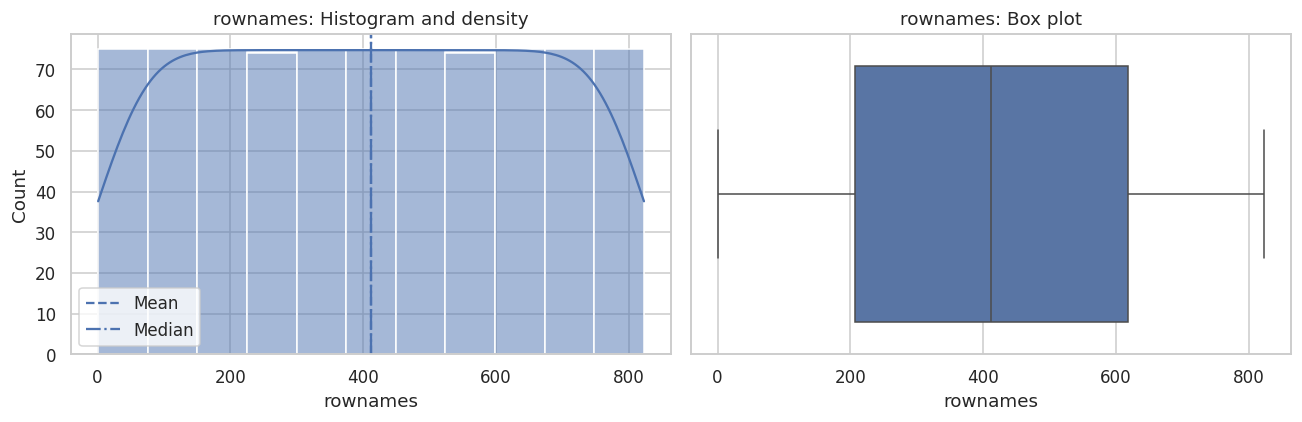

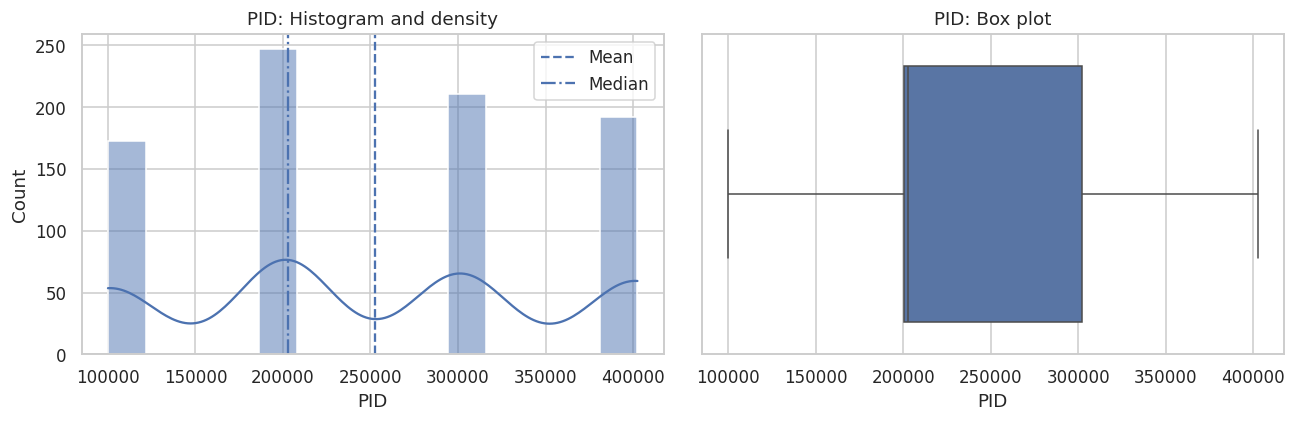

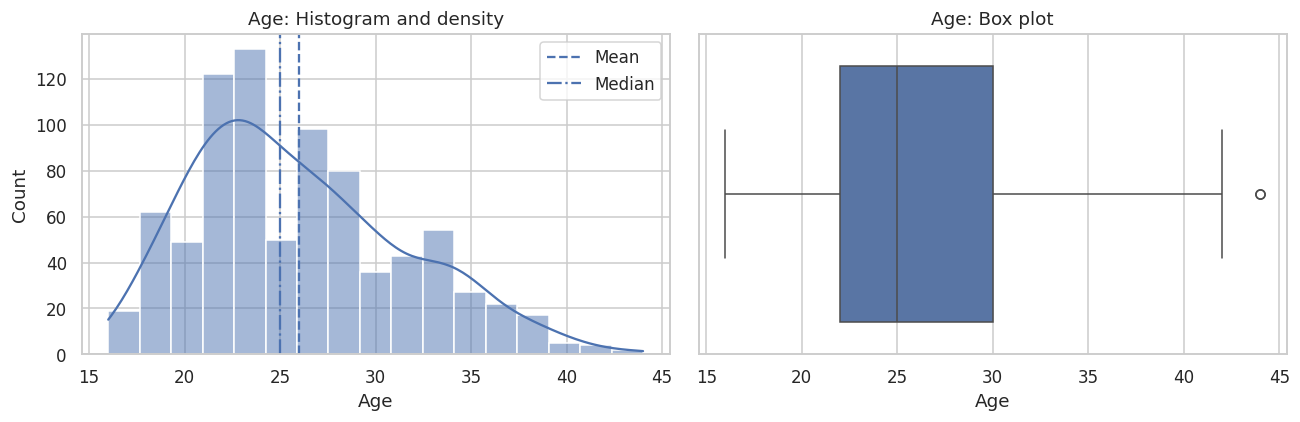

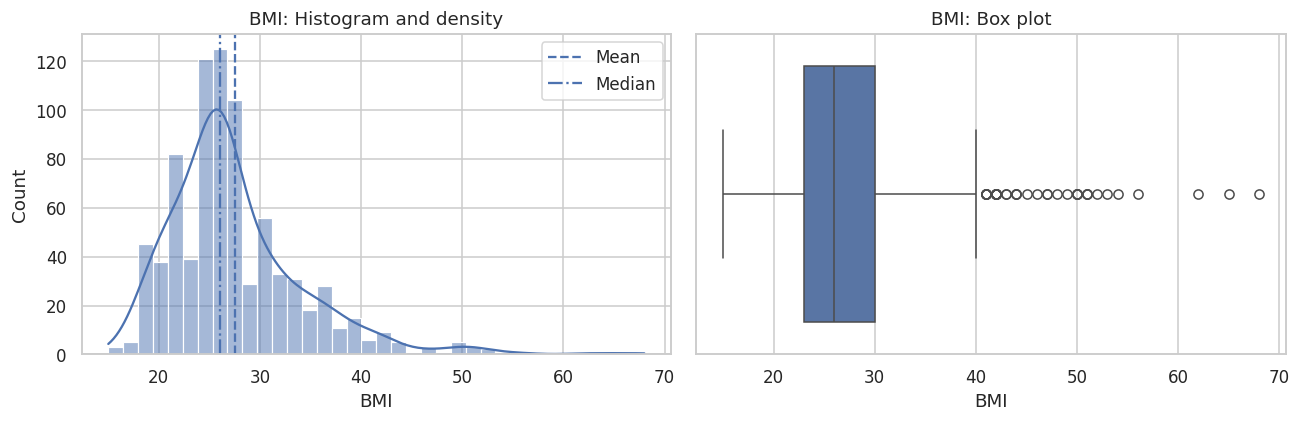

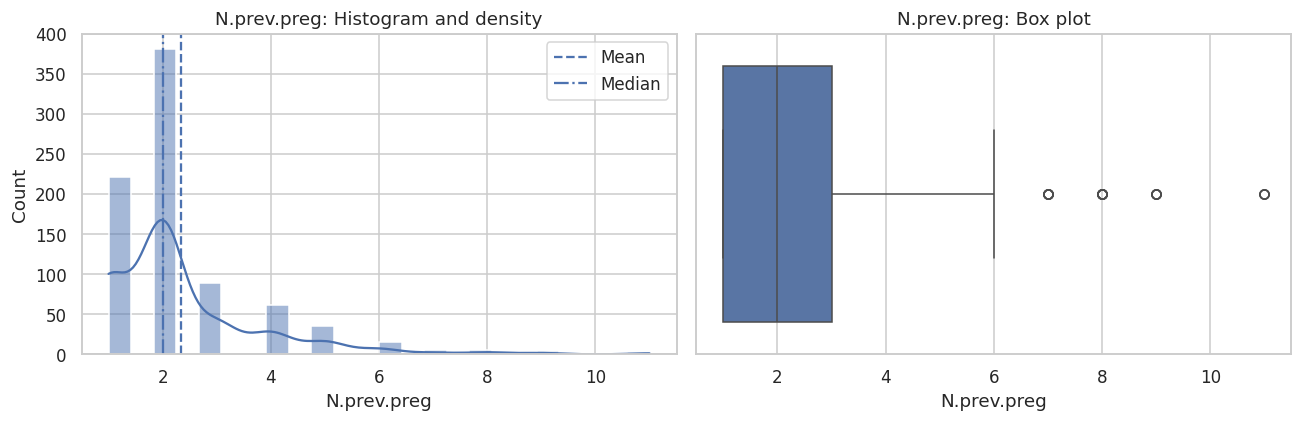

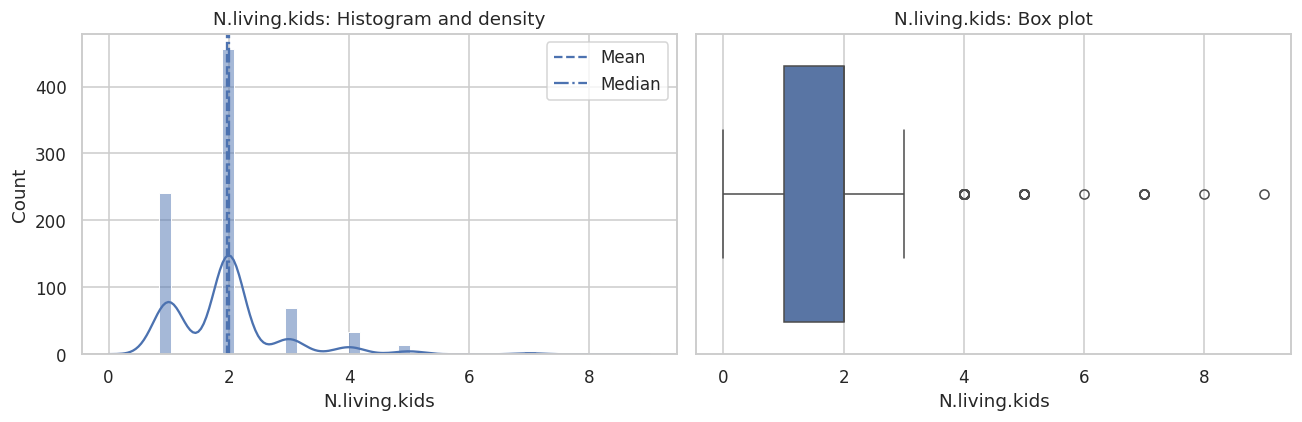

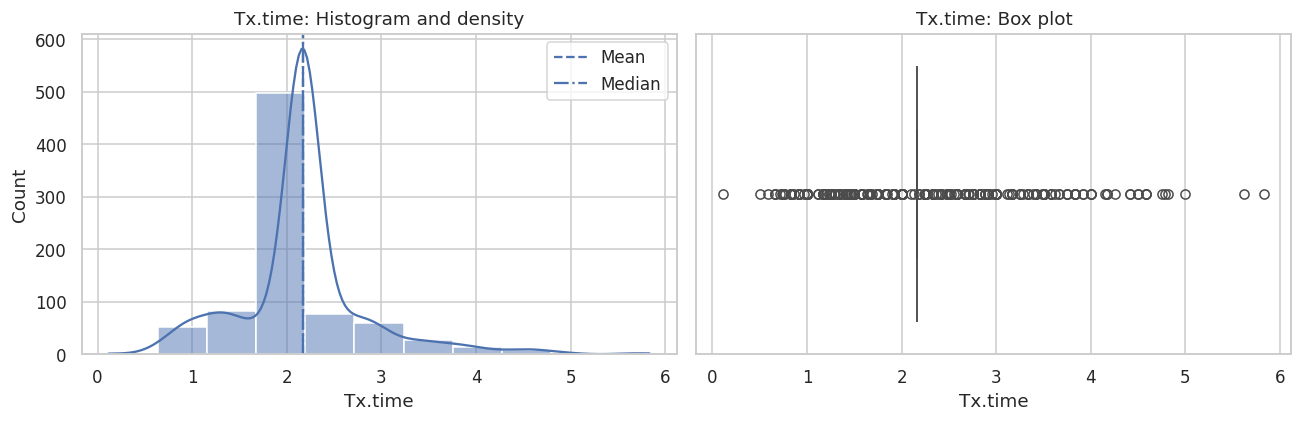

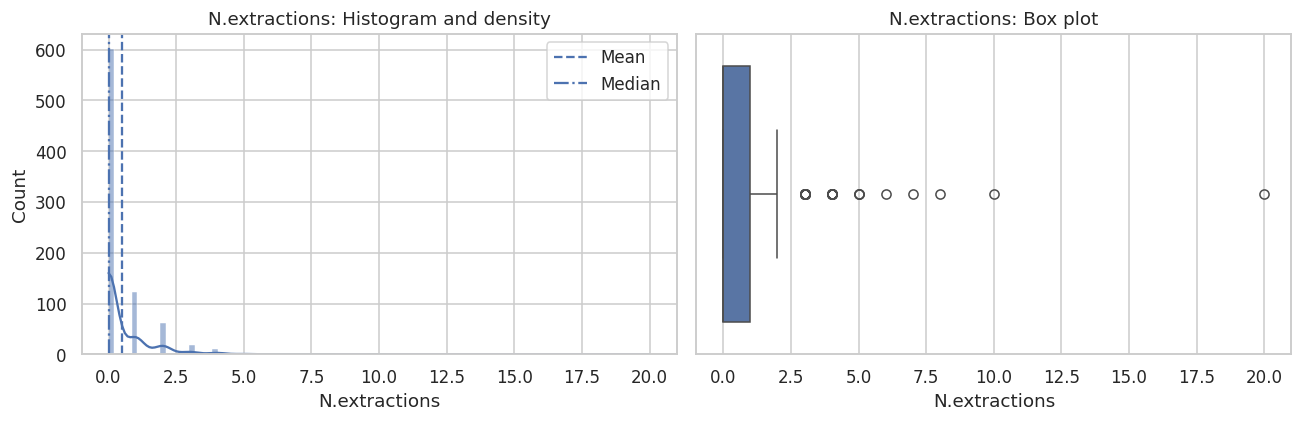

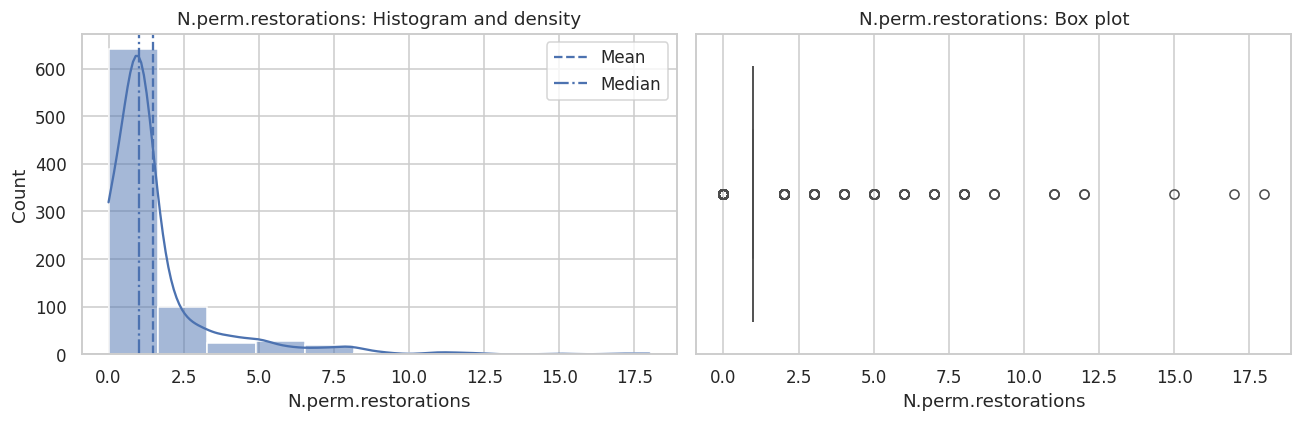

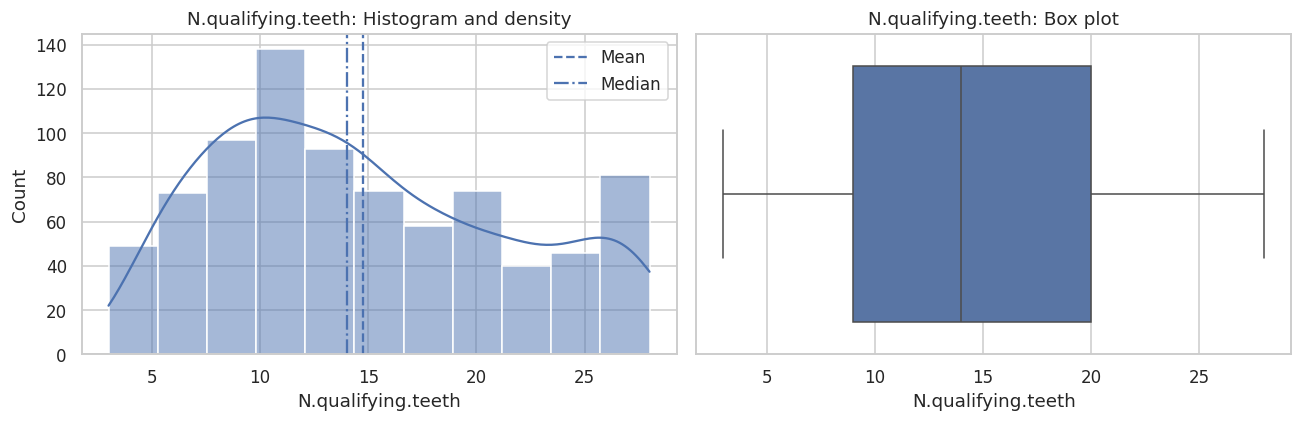

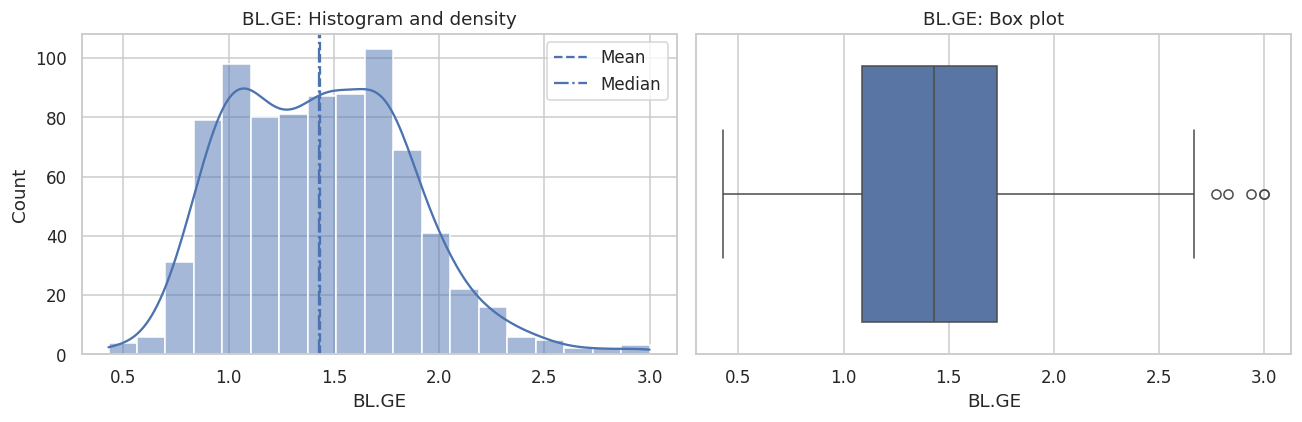

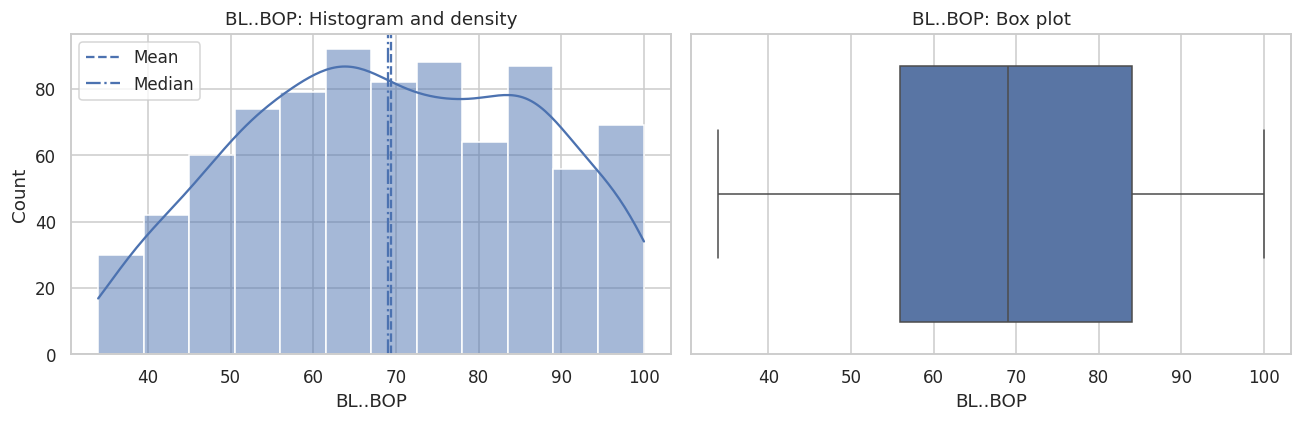

In [ ]:
num_cols = df.select_dtypes(include=np.number).columns.tolist()
cat_cols = df.select_dtypes(include=["object", "category", "bool"]).columns.tolist()

if num_cols:
    numeric_stats = pd.DataFrame(index=num_cols)
    numeric_stats["mean"] = df[num_cols].mean()
    numeric_stats["median"] = df[num_cols].median()
    numeric_stats["minimum"] = df[num_cols].min()
    numeric_stats["maximum"] = df[num_cols].max()
    numeric_stats["range"] = df[num_cols].max() - df[num_cols].min()
    numeric_stats["variance"] = df[num_cols].var()
    numeric_stats["std_dev"] = df[num_cols].std()
    numeric_stats["IQR"] = df[num_cols].quantile(.75) - df[num_cols].quantile(.25)
    numeric_stats["skewness"] = df[num_cols].skew()
    numeric_stats["kurtosis"] = df[num_cols].kurtosis()
    display(numeric_stats.round(4))

    for col in num_cols[:12]:
        fig, axes = plt.subplots(1, 2, figsize=(12, 4))
        sns.histplot(df[col], kde=True, ax=axes[0])
        axes[0].axvline(df[col].mean(), linestyle="--", label="Mean")
        axes[0].axvline(df[col].median(), linestyle="-.", label="Median")
        axes[0].set_title(f"{col}: Histogram and density")
        axes[0].legend()
        sns.boxplot(x=df[col], ax=axes[1])
        axes[1].set_title(f"{col}: Box plot")
        plt.tight_layout()
        plt.show()
else:
    print("No numeric columns were found.")

6. Univariate analysis — categorical variables

Frequency distribution: Clinic


,frequency,proportion,percentage
Clinic,,,
MN,247,0.300122,30.01
KY,211,0.256379,25.64
MS,192,0.233293,23.33
NY,173,0.210207,21.02


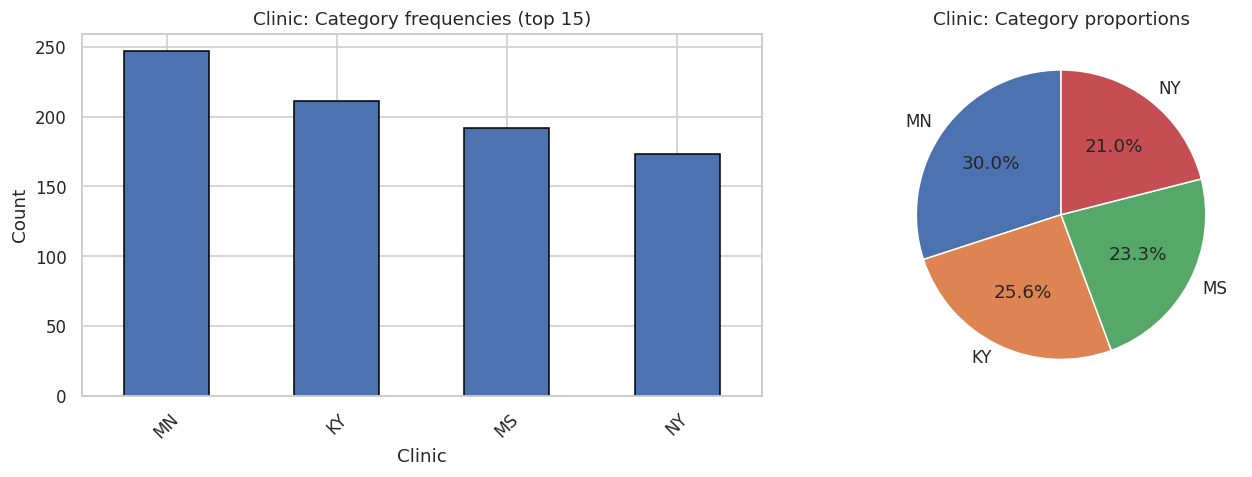

Frequency distribution: Group


,frequency,proportion,percentage
Group,,,
T,413,0.501823,50.18
C,410,0.498177,49.82


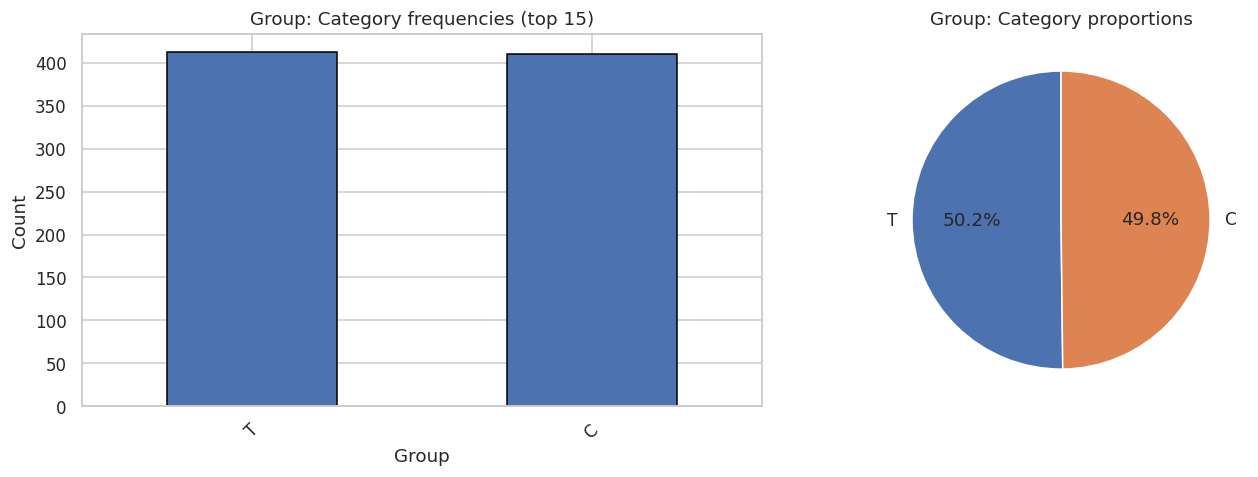

Frequency distribution: Black


,frequency,proportion,percentage
Black,,,
No,451,0.547995,54.8
Yes,372,0.452005,45.2


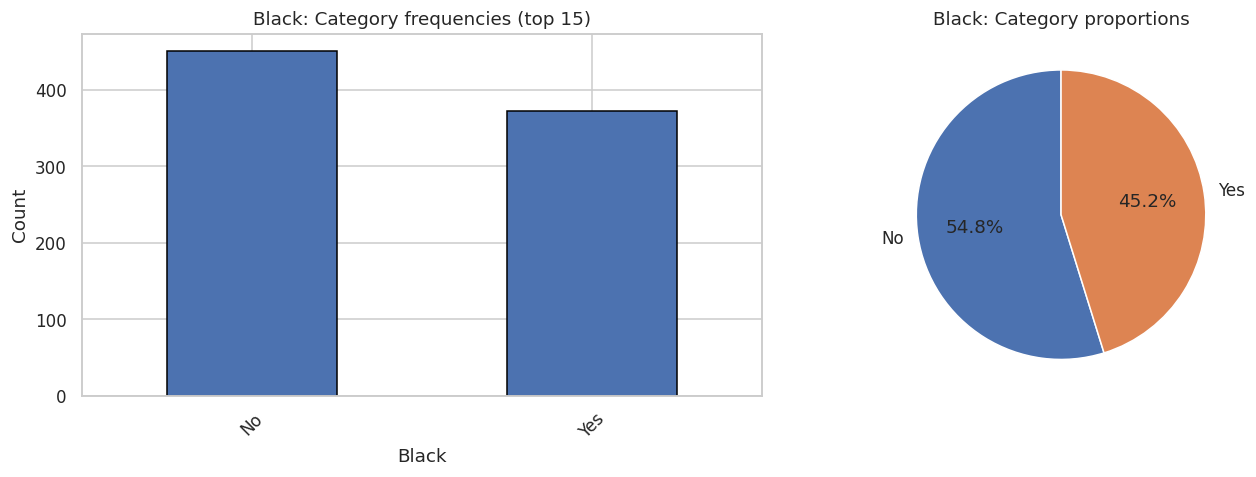

Frequency distribution: White


,frequency,proportion,percentage
White,,,
No,588,0.714459,71.45
Yes,235,0.285541,28.55


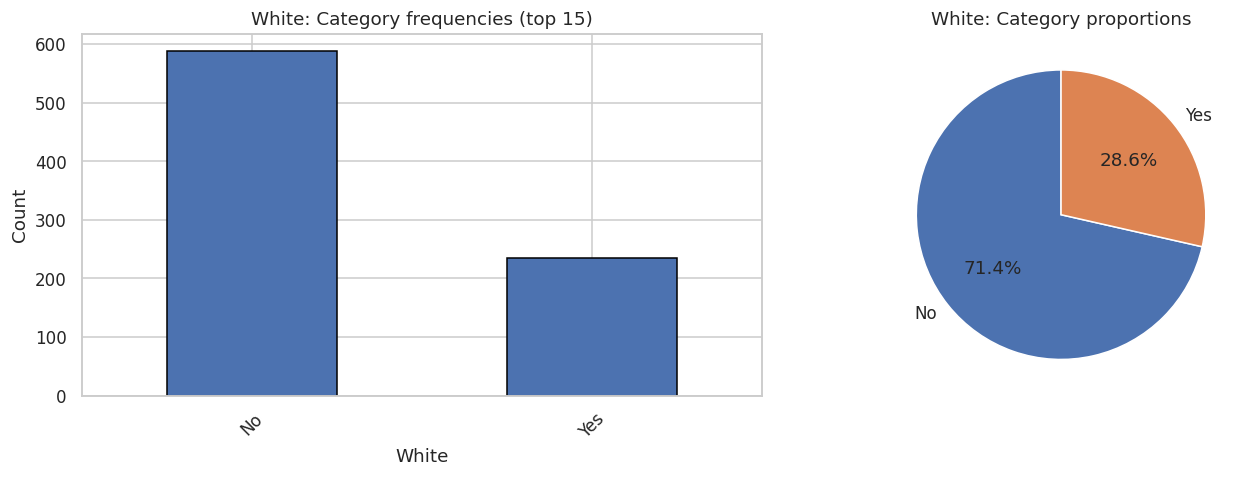

Frequency distribution: Nat.Am


,frequency,proportion,percentage
Nat.Am,,,
No,573,0.696233,69.62
Yes,250,0.303767,30.38


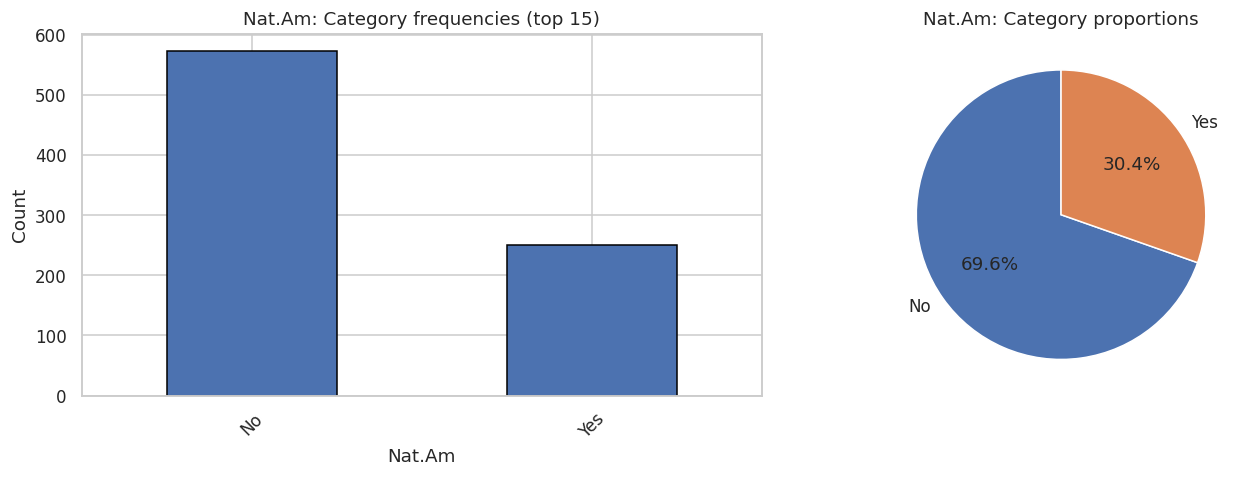

Frequency distribution: Asian


,frequency,proportion,percentage
Asian,,,
No,816,0.991495,99.15
Yes,7,0.008505,0.85


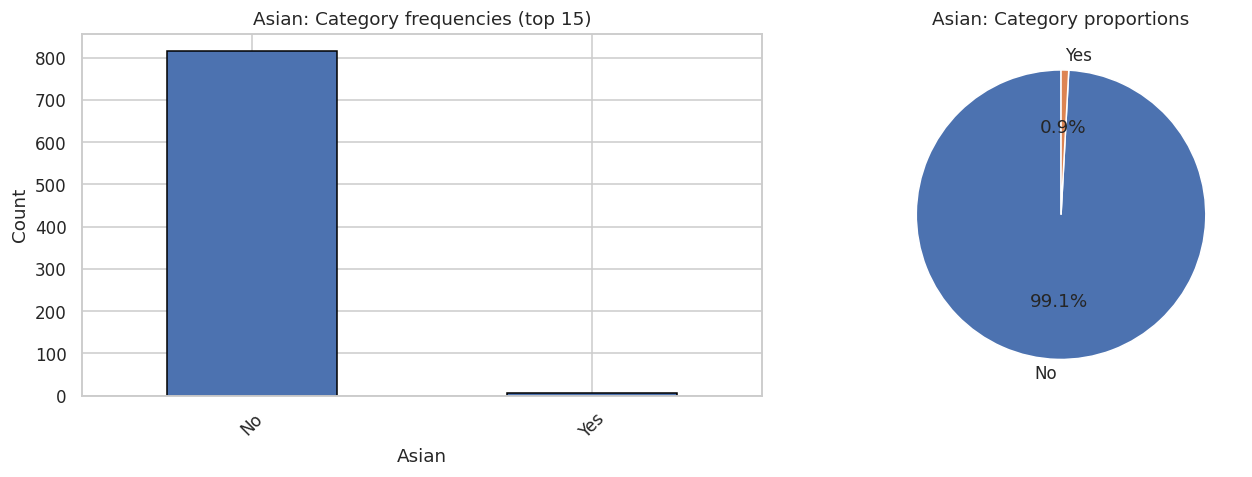

Frequency distribution: Hisp


,frequency,proportion,percentage
Hisp,,,
Yes,350,0.425273,42.53
No,328,0.398542,39.85
,145,0.176185,17.62


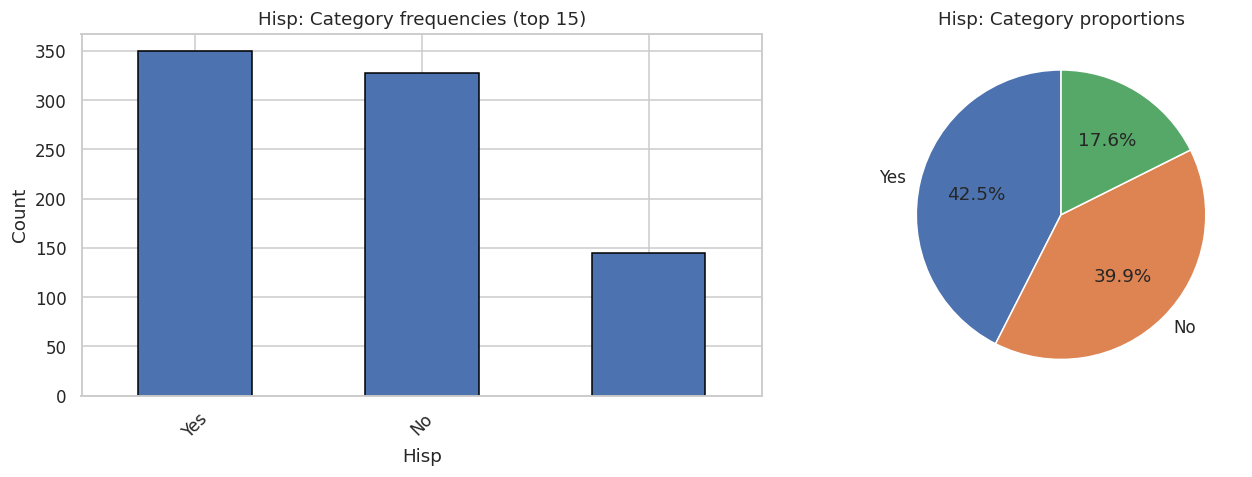

Frequency distribution: Education


,frequency,proportion,percentage
Education,,,
8-12 yrs,479,0.582017,58.20
MT 12 yrs,190,0.230863,23.09
LT 8 yrs,154,0.187120,18.71


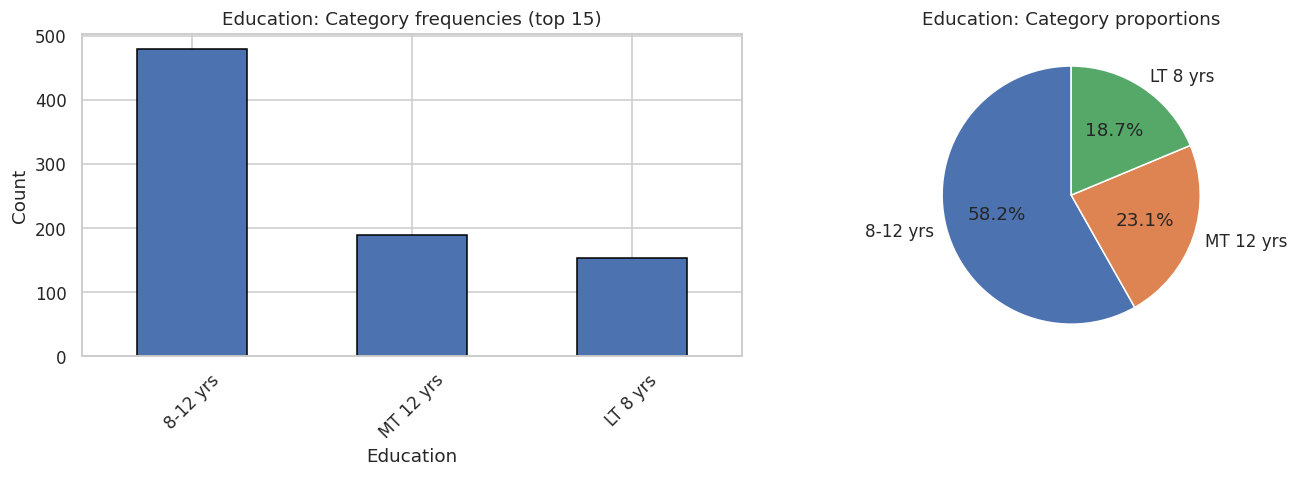

Frequency distribution: Public.Asstce


,frequency,proportion,percentage
Public.Asstce,,,
Yes,601,0.730255,73.03
No,222,0.269745,26.97


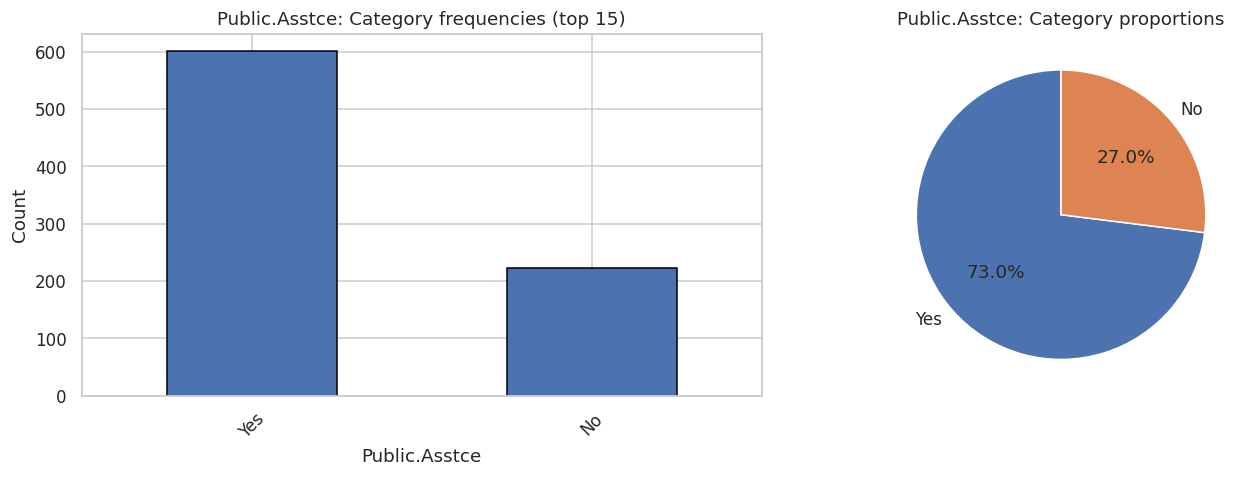

Frequency distribution: Hypertension


,frequency,proportion,percentage
Hypertension,,,
N,798,0.969623,96.96
Y,25,0.030377,3.04


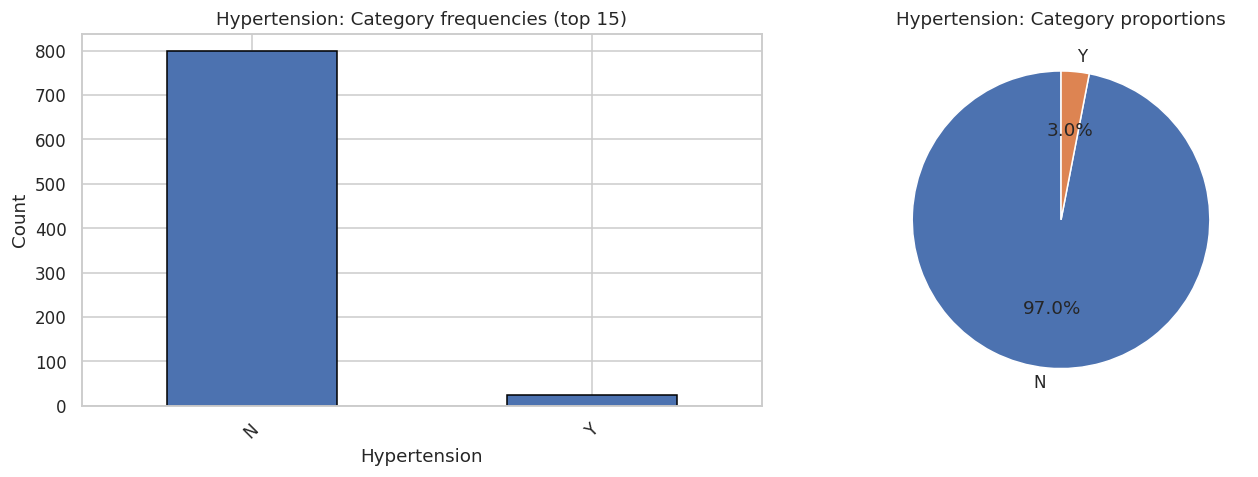

In [ ]:
if cat_cols:
    for col in cat_cols[:10]:
        counts = df[col].value_counts(dropna=False)
        proportions = (counts / counts.sum()).rename("proportion")
        freq_table = pd.concat([counts.rename("frequency"), proportions], axis=1)
        freq_table["percentage"] = (freq_table["proportion"] * 100).round(2)
        print(f"Frequency distribution: {col}")
        display(freq_table)

        plot_counts = counts.head(15)
        fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
        plot_counts.plot(kind="bar", ax=axes[0], edgecolor="black")
        axes[0].set_title(f"{col}: Category frequencies (top 15)")
        axes[0].set_xlabel(col)
        axes[0].set_ylabel("Count")
        axes[0].tick_params(axis="x", rotation=45)

        if len(counts) <= 8:
            axes[1].pie(counts.values, labels=counts.index.astype(str),
                        autopct="%1.1f%%", startangle=90)
            axes[1].set_title(f"{col}: Category proportions")
        else:
            (counts.head(15) / counts.sum() * 100).plot(kind="bar", ax=axes[1])
            axes[1].set_title(f"{col}: Percentage (top 15)")
            axes[1].set_ylabel("Percent")
            axes[1].tick_params(axis="x", rotation=45)
        plt.tight_layout()
        plt.show()
else:
    print("No categorical columns were found.")

7. Bivariate analysis — numerical versus numerical

,rownames,PID,Age,BMI,N.prev.preg
rownames,1.000,0.968,-0.140,0.146,-0.080
PID,0.968,1.000,-0.154,0.155,-0.099
Age,-0.140,-0.154,1.000,0.120,0.340
BMI,0.146,0.155,0.120,1.000,0.065
N.prev.preg,-0.080,-0.099,0.340,0.065,1.000


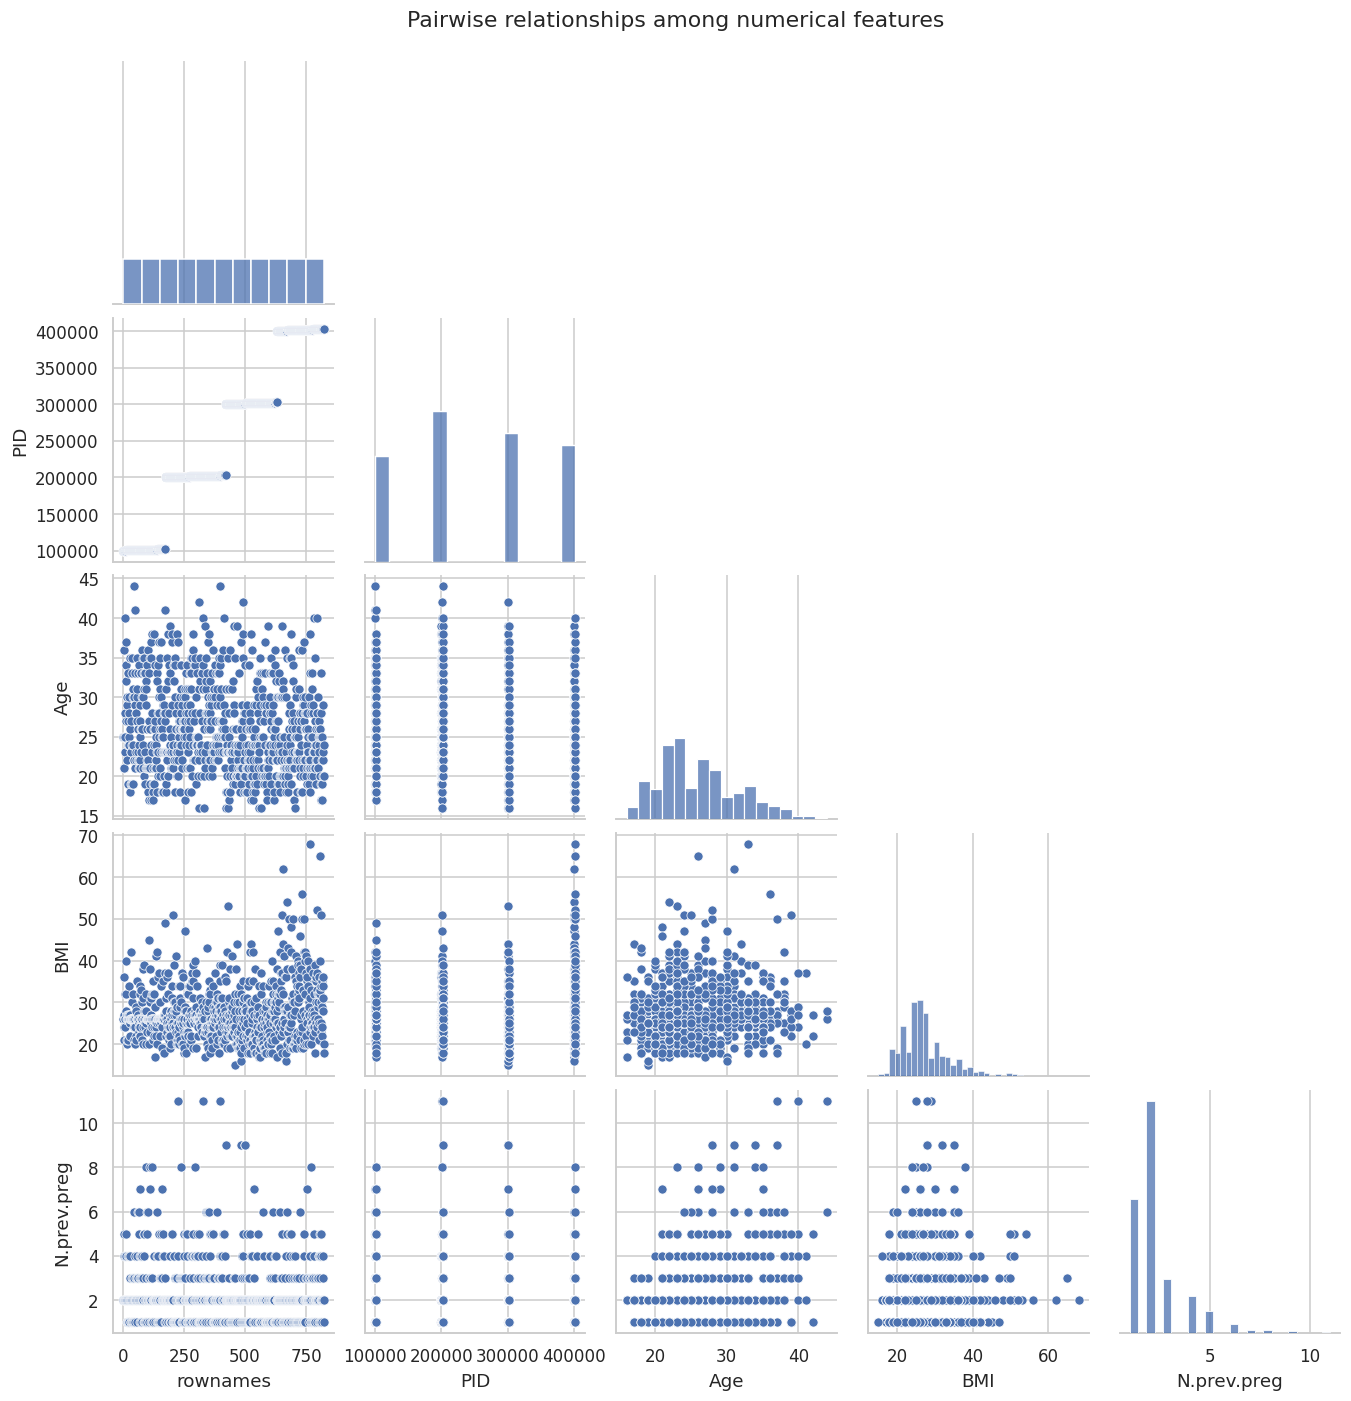

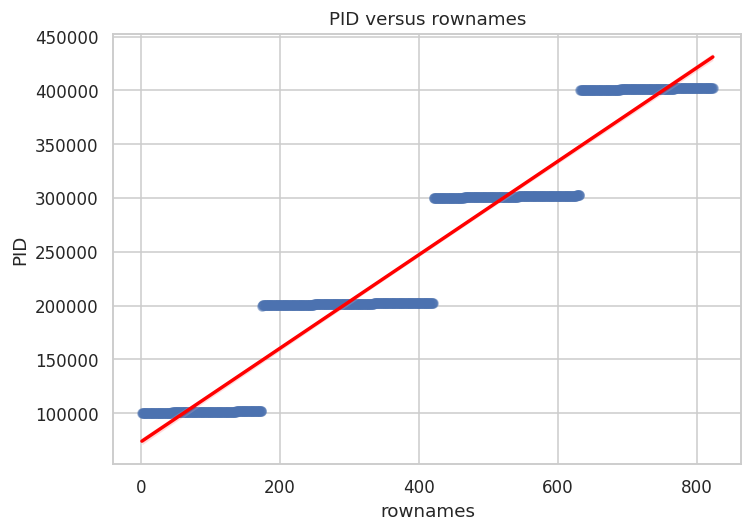

Pearson correlation: 0.9678179867833143
Spearman correlation: 1.0


In [ ]:
num_cols = df.select_dtypes(include=np.number).columns.tolist()
if len(num_cols) >= 2:
    chosen_num = num_cols[:min(5, len(num_cols))]
    display(df[chosen_num].corr(method="pearson").round(3))

    # Pair plot on a sample so it remains responsive for larger datasets
    pair_data = df[chosen_num].dropna()
    if len(pair_data) > 1000:
        pair_data = pair_data.sample(1000, random_state=42)
    sns.pairplot(pair_data, corner=True, diag_kind="hist")
    plt.suptitle("Pairwise relationships among numerical features", y=1.02)
    plt.show()

    x_col, y_col = num_cols[0], num_cols[1]
    plt.figure(figsize=(7, 5))
    sns.regplot(data=df, x=x_col, y=y_col,
                scatter_kws={"alpha": 0.45}, line_kws={"color": "red"})
    plt.title(f"{y_col} versus {x_col}")
    plt.tight_layout()
    plt.show()

    print("Pearson correlation:", df[x_col].corr(df[y_col], method="pearson"))
    print("Spearman correlation:", df[x_col].corr(df[y_col], method="spearman"))
else:
    print("At least two numeric columns are needed for this section.")

8. Bivariate analysis — categorical versus numerical

rownames grouped by Clinic


,count,mean,median,std,min,max
Clinic,,,,,,
MN,247,297.0,297.0,71.446950,174,420
KY,211,526.0,526.0,61.054620,421,631
MS,192,727.5,727.5,55.569776,632,823
NY,173,87.0,87.0,50.084928,1,173


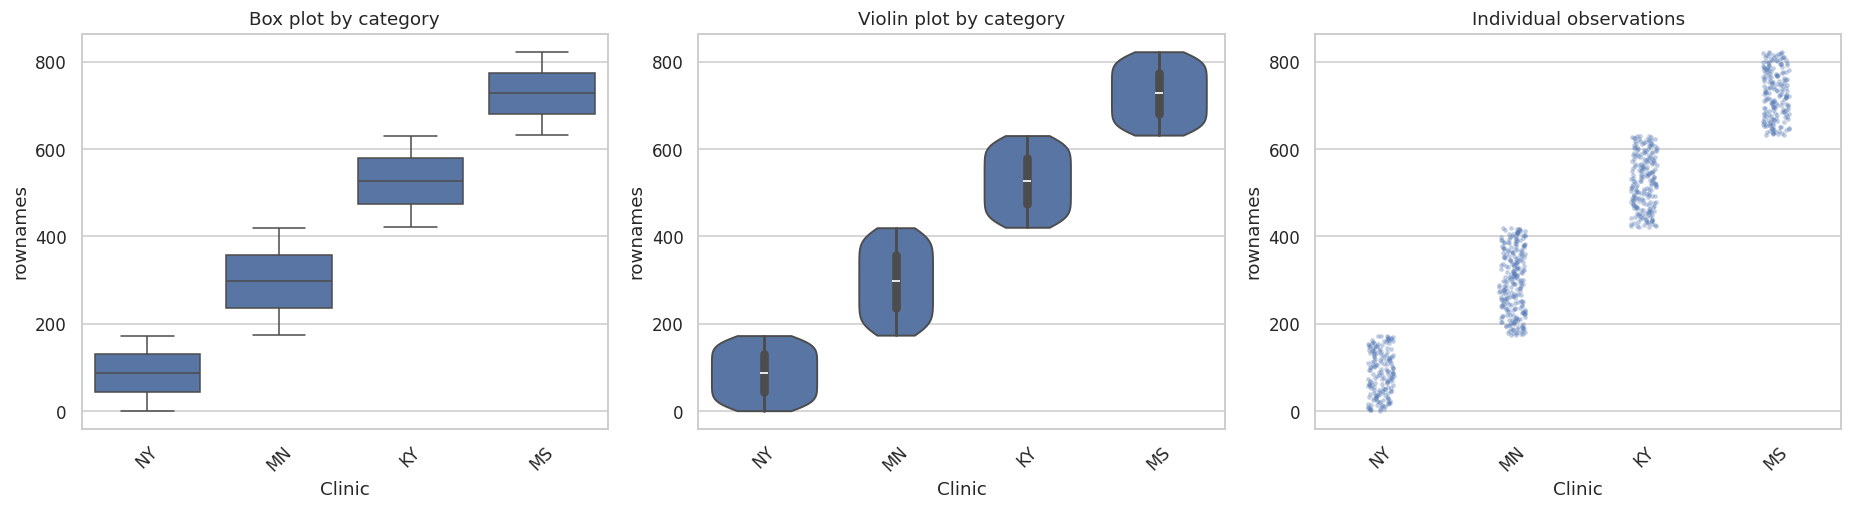

In [ ]:
num_cols = df.select_dtypes(include=np.number).columns.tolist()
cat_cols = df.select_dtypes(include=["object", "category", "bool"]).columns.tolist()

if num_cols and cat_cols:
    numeric_col = num_cols[0]
    categorical_col = cat_cols[0]
    # Limit to the 10 most frequent categories for readable plots
    top_categories = df[categorical_col].value_counts().head(10).index
    plot_df = df[df[categorical_col].isin(top_categories)].copy()

    grouped_stats = plot_df.groupby(categorical_col, observed=False)[numeric_col].agg(
        ["count", "mean", "median", "std", "min", "max"]
    ).sort_values("count", ascending=False)
    print(f"{numeric_col} grouped by {categorical_col}")
    display(grouped_stats)

    fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
    sns.boxplot(data=plot_df, x=categorical_col, y=numeric_col, ax=axes[0])
    axes[0].set_title("Box plot by category")
    axes[0].tick_params(axis="x", rotation=45)

    sns.violinplot(data=plot_df, x=categorical_col, y=numeric_col, ax=axes[1], cut=0)
    axes[1].set_title("Violin plot by category")
    axes[1].tick_params(axis="x", rotation=45)

    sns.stripplot(data=plot_df, x=categorical_col, y=numeric_col, ax=axes[2],
                  alpha=.35, size=3)
    axes[2].set_title("Individual observations")
    axes[2].tick_params(axis="x", rotation=45)
    plt.tight_layout()
    plt.show()
else:
    print("Need at least one numeric and one categorical column.")

9. Categorical versus categorical — contingency tables and bar plots

Contingency table:


Group,C,T
Clinic,,
KY,105,106
MN,123,124
MS,96,96
NY,86,87


Row percentages:


Group,C,T
Clinic,,
KY,49.76,50.24
MN,49.80,50.20
MS,50.00,50.00
NY,49.71,50.29


Column percentages:


Group,C,T
Clinic,,
KY,25.61,25.67
MN,30.00,30.02
MS,23.41,23.24
NY,20.98,21.07


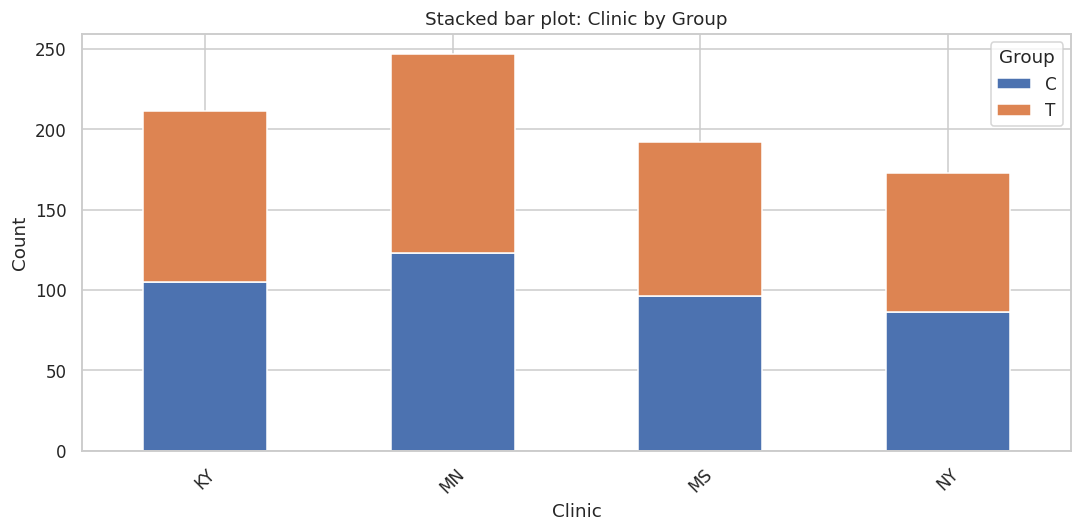

Chi-square test: statistic=0.0036, p-value=0.999942, df=3


In [ ]:
cat_cols = df.select_dtypes(include=["object", "category", "bool"]).columns.tolist()
if len(cat_cols) >= 2:
    c1, c2 = cat_cols[0], cat_cols[1]
    # Use top categories to keep tables and charts readable
    keep1 = df[c1].value_counts().head(10).index
    keep2 = df[c2].value_counts().head(10).index
    temp = df[df[c1].isin(keep1) & df[c2].isin(keep2)]
    ct = pd.crosstab(temp[c1], temp[c2])
    print("Contingency table:")
    display(ct)
    print("Row percentages:")
    display((pd.crosstab(temp[c1], temp[c2], normalize="index") * 100).round(2))
    print("Column percentages:")
    display((pd.crosstab(temp[c1], temp[c2], normalize="columns") * 100).round(2))

    ct.plot(kind="bar", stacked=True, figsize=(10, 5))
    plt.title(f"Stacked bar plot: {c1} by {c2}")
    plt.ylabel("Count")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

    if ct.shape[0] > 1 and ct.shape[1] > 1:
        chi2, p, dof, expected = chi2_contingency(ct)
        print(f"Chi-square test: statistic={chi2:.4f}, p-value={p:.6g}, df={dof}")
else:
    print("Need at least two categorical columns.")

10. Multivariate analysis

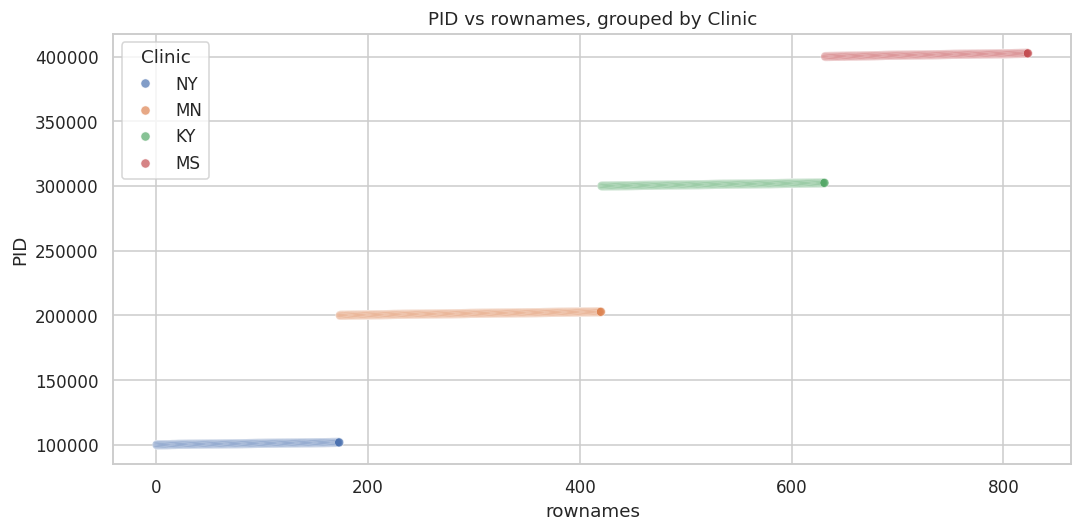

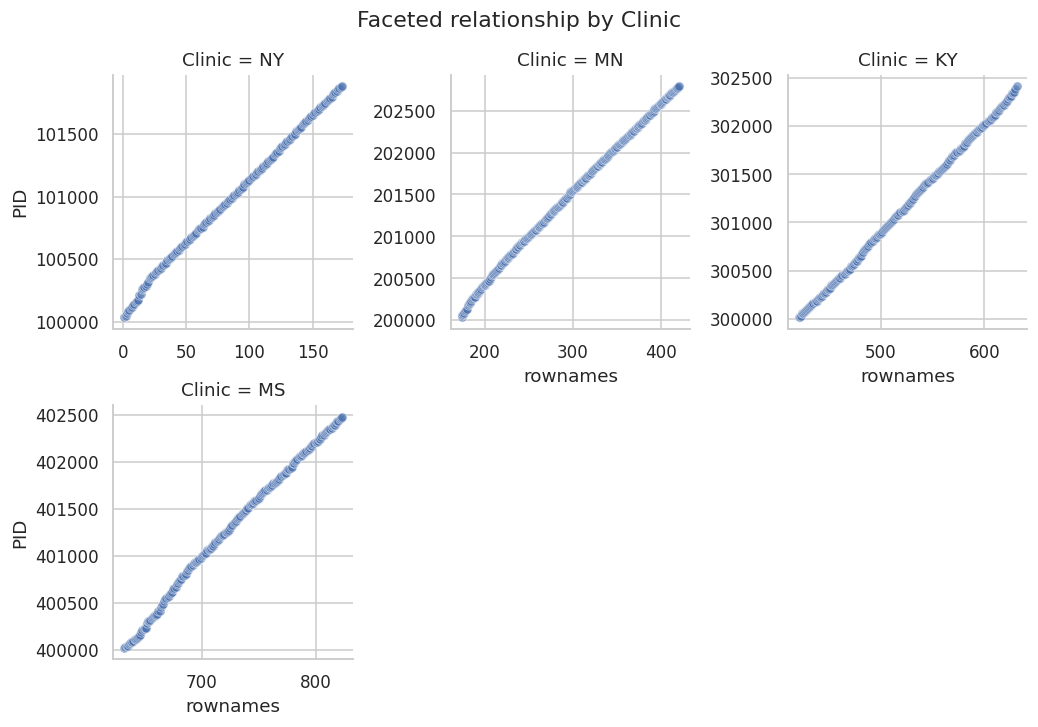

In [ ]:
num_cols = df.select_dtypes(include=np.number).columns.tolist()
cat_cols = df.select_dtypes(include=["object", "category", "bool"]).columns.tolist()

if len(num_cols) >= 2 and cat_cols:
    x_col, y_col, hue_col = num_cols[0], num_cols[1], cat_cols[0]
    top = df[hue_col].value_counts().head(8).index
    plot_df = df[df[hue_col].isin(top)].copy()
    sns.scatterplot(data=plot_df, x=x_col, y=y_col, hue=hue_col, alpha=.7)
    plt.title(f"{y_col} vs {x_col}, grouped by {hue_col}")
    plt.tight_layout()
    plt.show()

    # Faceted view using the most frequent categories
    try:
        g = sns.FacetGrid(plot_df, col=hue_col, col_wrap=3, height=3.2, sharex=False, sharey=False)
        g.map_dataframe(sns.scatterplot, x=x_col, y=y_col, alpha=.6)
        g.fig.suptitle(f"Faceted relationship by {hue_col}", y=1.03)
        plt.show()
    except Exception as e:
        print("Facet plot skipped:", e)

elif len(num_cols) >= 3:
    sns.scatterplot(data=df, x=num_cols[0], y=num_cols[1], size=num_cols[2],
                    sizes=(20, 250), alpha=.6, legend=False)
    plt.title("Bubble plot using three numerical features")
    plt.tight_layout()
    plt.show()
else:
    print("Not enough suitable columns for multivariate plots.")

11. Correlation analysis and heatmap

,rownames,PID,Age,BMI,N.prev.preg,N.living.kids,Tx.time,N.extractions,N.perm.restorations,N.qualifying.teeth,BL.GE,BL..BOP,BL.PD.avg,BL..PD.4,BL..PD.5
rownames,1.000,0.968,-0.140,0.146,-0.080,-0.017,0.088,0.119,-0.074,-0.023,-0.250,-0.122,-0.104,-0.086,-0.209
PID,0.968,1.000,-0.154,0.155,-0.099,-0.029,0.081,0.102,-0.086,-0.005,-0.298,-0.141,-0.113,-0.089,-0.212
Age,-0.140,-0.154,1.000,0.120,0.340,0.303,0.118,0.083,0.023,0.117,0.151,0.134,0.193,0.187,0.219
BMI,0.146,0.155,0.120,1.000,0.065,0.018,0.016,0.050,0.006,0.042,0.114,0.078,0.057,0.055,0.021
N.prev.preg,-0.080,-0.099,0.340,0.065,1.000,0.730,0.018,0.098,0.012,0.046,0.100,0.003,0.048,0.035,0.050
N.living.kids,-0.017,-0.029,0.303,0.018,0.730,1.000,0.021,0.095,0.018,0.028,0.045,0.011,0.038,0.022,0.023
Tx.time,0.088,0.081,0.118,0.016,0.018,0.021,1.000,0.058,0.003,0.240,0.103,0.180,0.294,0.307,0.240
N.extractions,0.119,0.102,0.083,0.050,0.098,0.095,0.058,1.000,0.058,-0.029,0.067,0.074,0.131,0.081,0.069
N.perm.restorations,-0.074,-0.086,0.023,0.006,0.012,0.018,0.003,0.058,1.000,0.037,0.115,0.083,0.055,0.090,0.128
N.qualifying.teeth,-0.023,-0.005,0.117,0.042,0.046,0.028,0.240,-0.029,0.037,1.000,0.330,0.475,0.767,0.823,0.694


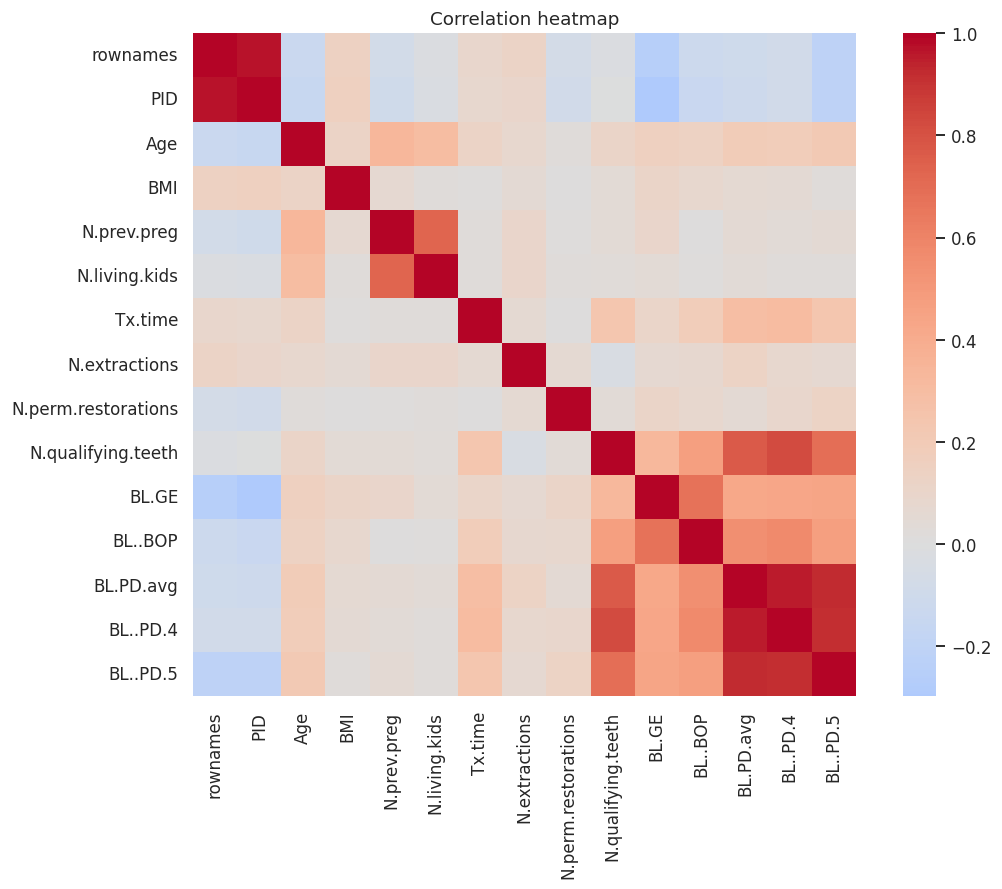

In [ ]:
num_cols = df.select_dtypes(include=np.number).columns.tolist()
if len(num_cols) >= 2:
    corr_cols = num_cols[:min(15, len(num_cols))]
    corr_matrix = df[corr_cols].corr()
    display(corr_matrix.round(3))
    plt.figure(figsize=(max(8, len(corr_cols)*0.7), max(6, len(corr_cols)*0.55)))
    sns.heatmap(corr_matrix, annot=len(corr_cols) <= 10, fmt=".2f",
                cmap="coolwarm", center=0, square=True)
    plt.title("Correlation heatmap")
    plt.tight_layout()
    plt.show()
else:
    print("Not enough numeric columns for a correlation matrix.")

12. Outlier detection using the IQR method

,Feature,Lower IQR Bound,Upper IQR Bound,Outlier Count,Outlier %
0,rownames,-410.00,1234.00,0,0.00
1,PID,47940.50,454768.50,0,0.00
2,Age,10.00,42.00,2,0.24
3,BMI,12.50,40.50,40,4.86
4,N.prev.preg,-2.00,6.00,18,2.19
...,...,...,...,...,...
92,V5..TF,2.02,2.02,324,39.37
93,V5..PI,0.07,0.07,323,39.25
94,V5..CR,0.96,0.96,324,39.37
95,V5..FN,15.36,15.36,323,39.25


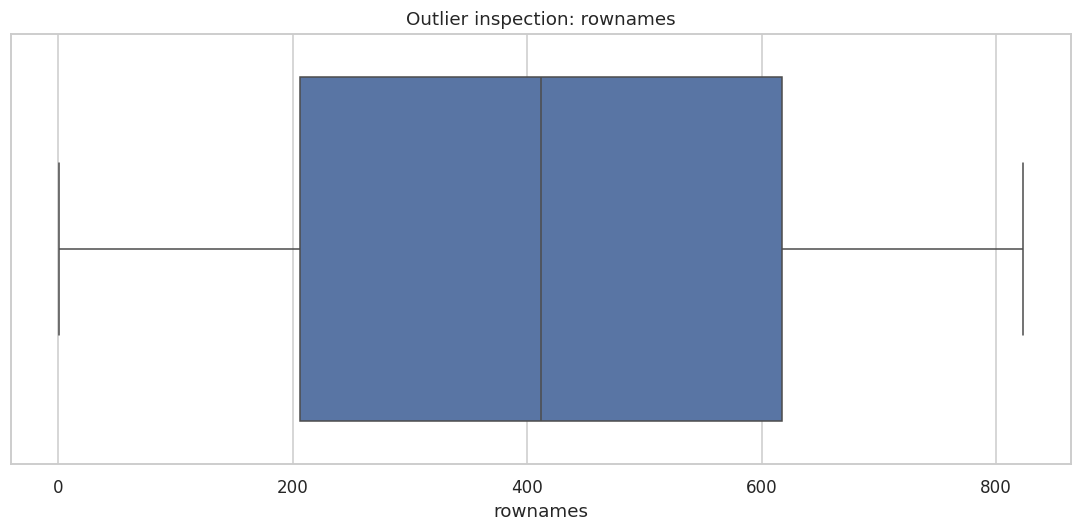

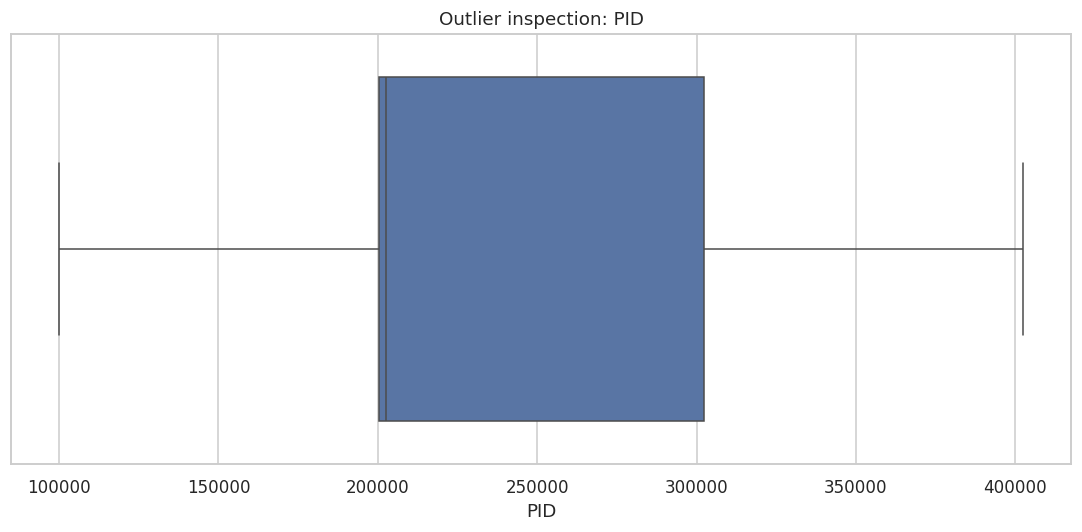

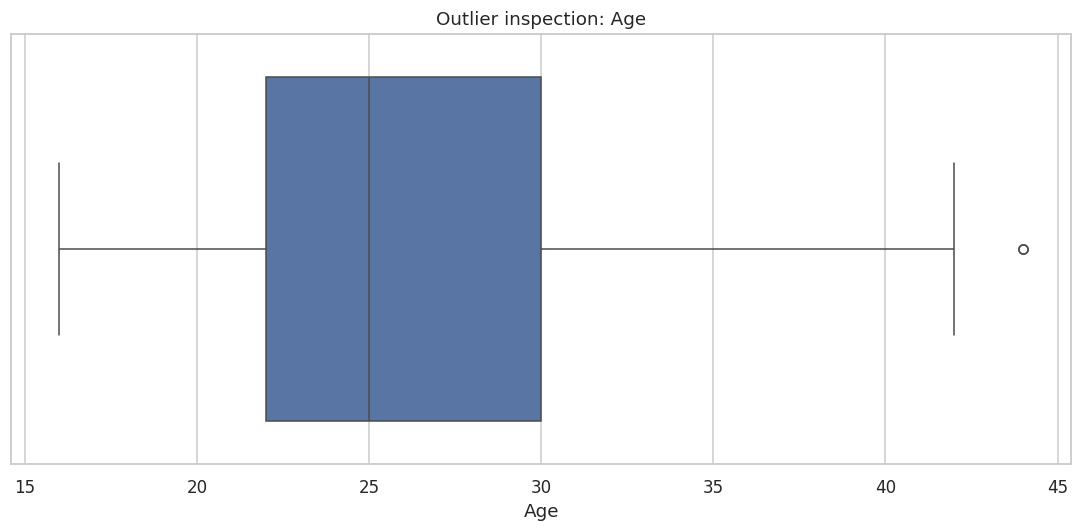

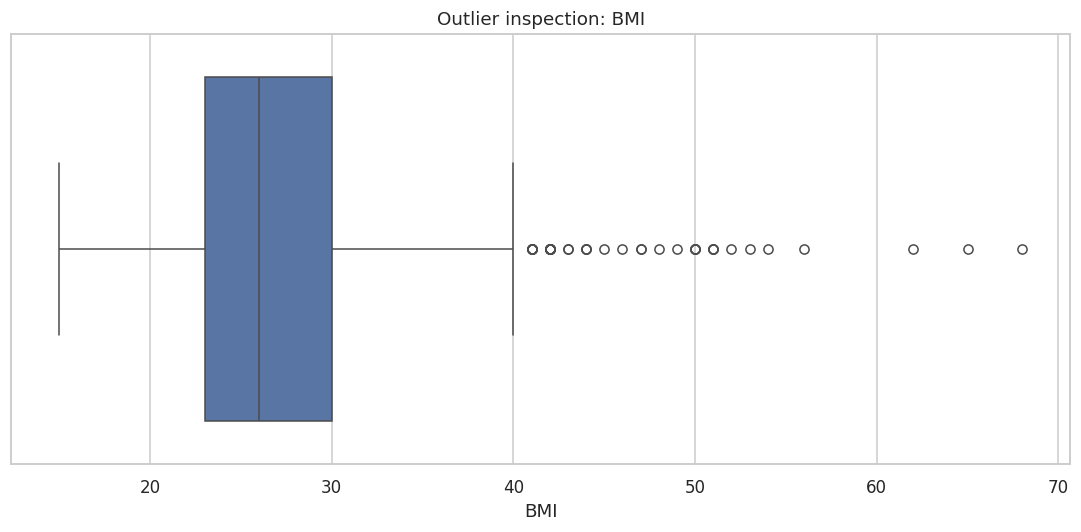

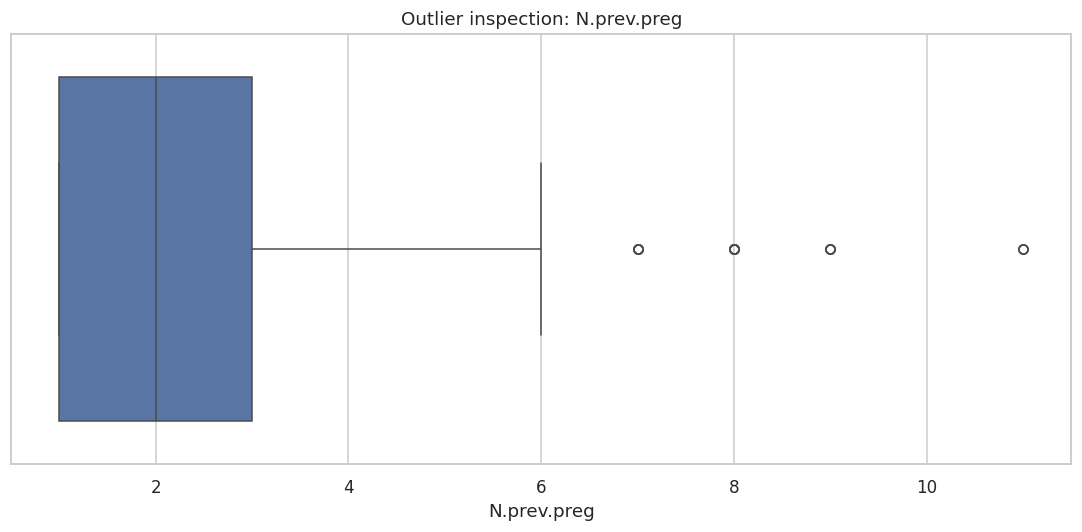

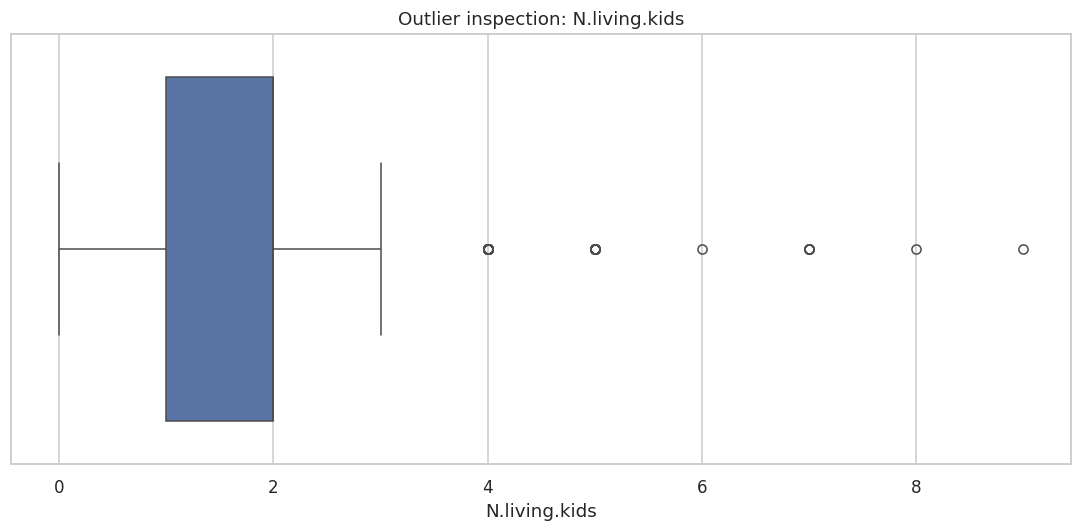

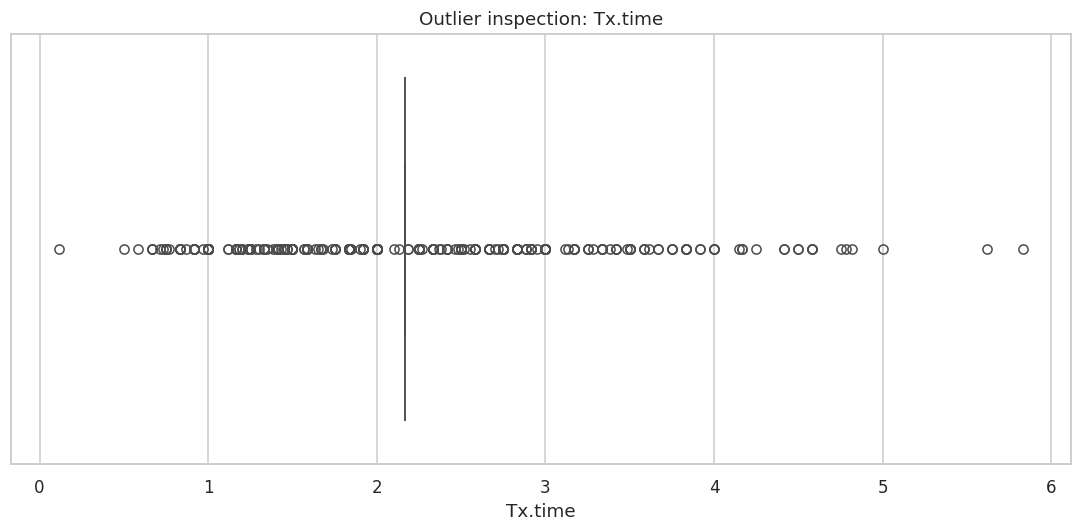

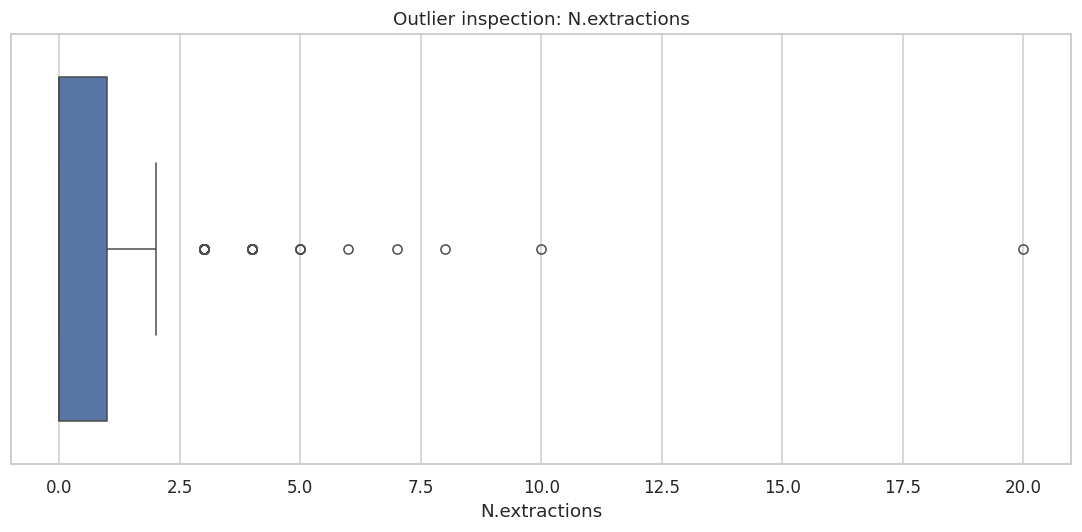

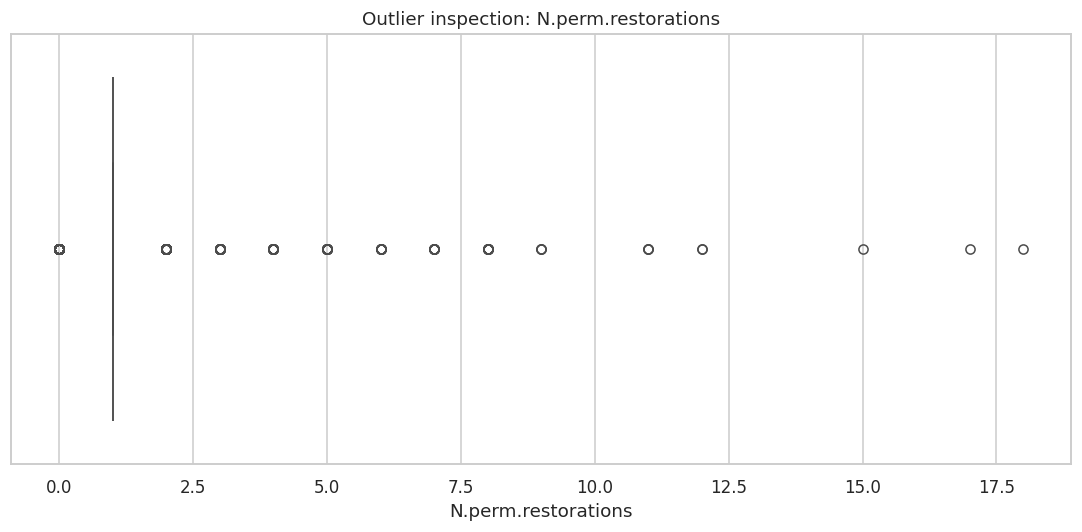

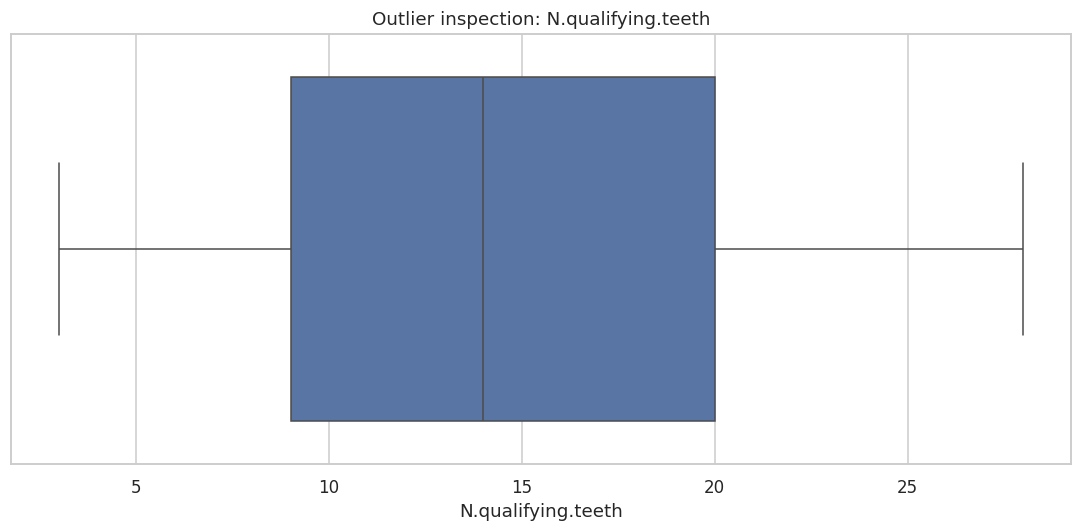

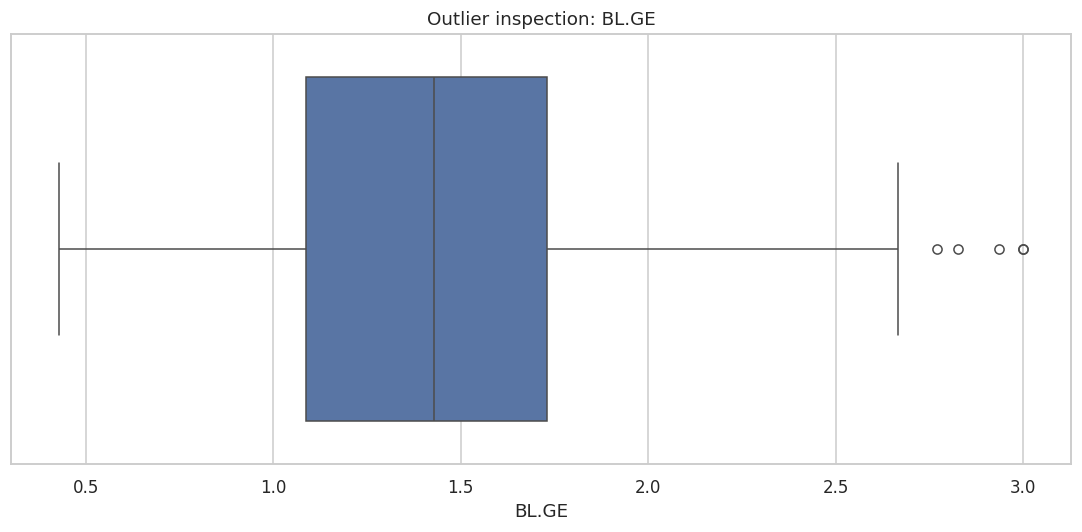

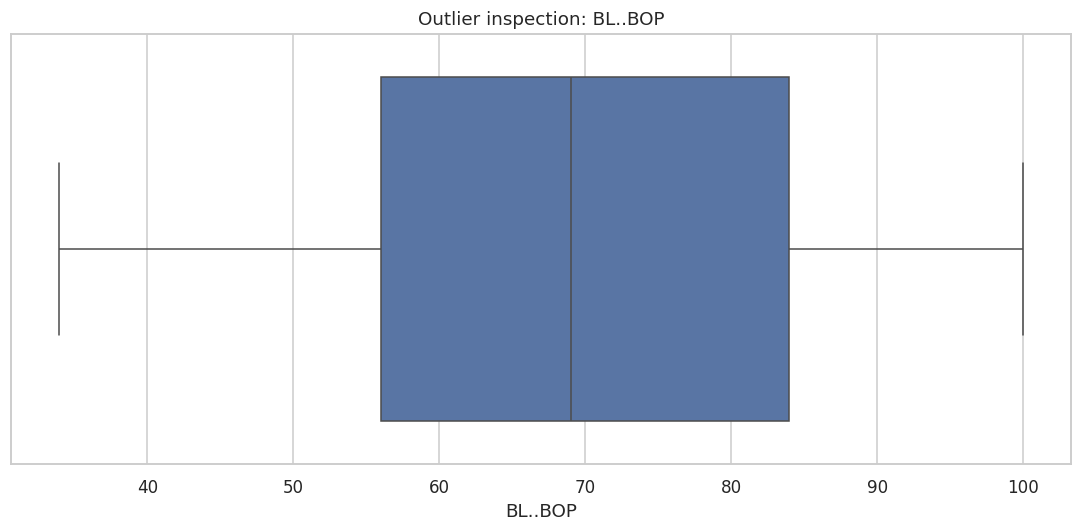

In [ ]:
num_cols = df.select_dtypes(include=np.number).columns.tolist()
outlier_rows = []
for col in num_cols:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5*iqr, q3 + 1.5*iqr
    count = int(((df[col] < lower) | (df[col] > upper)).sum())
    outlier_rows.append([col, lower, upper, count, round(count/len(df)*100, 2)])
outlier_table = pd.DataFrame(outlier_rows, columns=[
    "Feature", "Lower IQR Bound", "Upper IQR Bound", "Outlier Count", "Outlier %"
])
display(outlier_table)

# Show box plots; do not automatically delete outliers because they may be valid observations.
for col in num_cols[:12]:
    sns.boxplot(x=df[col])
    plt.title(f"Outlier inspection: {col}")
    plt.tight_layout()
    plt.show()

13. Statistical hypothesis testing

In [ ]:
num_cols = df.select_dtypes(include=np.number).columns.tolist()
cat_cols = df.select_dtypes(include=["object", "category", "bool"]).columns.tolist()

# Numerical variable across two categories: Mann–Whitney U; for >2 categories: Kruskal–Wallis.
if num_cols and cat_cols:
    numeric_col = num_cols[0]
    categorical_col = cat_cols[0]
    levels = df[categorical_col].value_counts().head(6).index.tolist()
    groups = [df.loc[df[categorical_col] == level, numeric_col].dropna() for level in levels]
    groups = [g for g in groups if len(g) > 0]

    if len(groups) == 2:
        statistic, p_value = mannwhitneyu(groups[0], groups[1], alternative="two-sided")
        test_name = "Mann–Whitney U"
    elif len(groups) >= 3:
        statistic, p_value = kruskal(*groups)
        test_name = "Kruskal–Wallis"
    else:
        statistic, p_value, test_name = np.nan, np.nan, "Not enough groups"

    print(f"{test_name} test for {numeric_col} across {categorical_col}")
    print("Statistic:", statistic)
    print("p-value:", p_value)
    if pd.notna(p_value):
        print("Interpretation at 5% significance:",
              "statistically significant difference (reject H0)" if p_value < 0.05
              else "insufficient evidence of a difference (do not reject H0)")
else:
    print("Need both numeric and categorical variables for group comparison.")

# Chi-square independence test for the first two categorical features
if len(cat_cols) >= 2:
    ct_test = pd.crosstab(df[cat_cols[0]], df[cat_cols[1]])
    if ct_test.shape[0] > 1 and ct_test.shape[1] > 1:
        chi2, p, dof, expected = chi2_contingency(ct_test)
        print(f"\nChi-square independence test: {cat_cols[0]} vs {cat_cols[1]}")
        print(f"Chi-square={chi2:.4f}, p-value={p:.6g}, degrees of freedom={dof}")

Kruskal–Wallis test for rownames across Clinic
Statistic: 767.8558907147662
p-value: 4.0490794408998557e-166
Interpretation at 5% significance: statistically significant difference (reject H0)

Chi-square independence test: Clinic vs Group
Chi-square=0.0036, p-value=0.999942, degrees of freedom=3


14. Feature engineering and distribution checks

In [ ]:
# Create a copy for engineered features. Example: z-scores for numeric columns.
df_analysis = df.copy()
num_cols = df_analysis.select_dtypes(include=np.number).columns.tolist()

for col in num_cols[:5]:
    std = df_analysis[col].std()
    if pd.notna(std) and std != 0:
        df_analysis[col + "_zscore"] = (df_analysis[col] - df_analysis[col].mean()) / std

print("Original shape:", df.shape)
print("Shape after adding up to five z-score features:", df_analysis.shape)
display(df_analysis.head())

# Shapiro-Wilk is limited to 5000 observations, so sample if necessary.
for col in num_cols[:8]:
    values = df[col].dropna()
    if len(values) >= 3:
        sample = values.sample( min(len(values), 5000), random_state=42) if len(values) > 5000 else values
        stat, p = stats.shapiro(sample)
        print(f"{col}: Shapiro statistic={stat:.4f}, p-value={p:.6g}",
              "-> evidence against normality" if p < 0.05 else "-> no strong evidence against normality")

Original shape: (823, 169)
Shape after adding up to five z-score features: (823, 174)


,rownames,PID,Clinic,Group,Age,Black,White,Nat.Am,Asian,Hisp,...,V5..TF,V5..PI,V5..CR,V5..FN,V5..S7,rownames_zscore,PID_zscore,Age_zscore,BMI_zscore,N.prev.preg_zscore
0,1,100034,NY,C,25,Yes,No,No,No,,...,2.02,0.07,0.96,15.36,28.19,-1.728896,-1.428814,-0.175734,-0.223059,-0.228471
1,2,100042,NY,C,21,Yes,No,No,No,,...,2.02,0.07,0.96,15.36,28.19,-1.724690,-1.428739,-0.894386,-0.956195,1.786157
2,3,100067,NY,T,25,No,Yes,No,No,Yes,...,2.02,0.07,0.96,15.36,28.19,-1.720483,-1.428504,-0.175734,-0.516313,-0.228471
3,4,100083,NY,C,36,Yes,No,No,No,,...,2.02,0.07,0.96,15.36,28.19,-1.716277,-1.428354,1.800560,1.243213,1.114614
4,5,100091,NY,C,21,No,Yes,No,No,Yes,...,2.02,0.07,0.96,15.36,28.19,-1.712070,-1.428279,-0.894386,-0.076431,-0.228471


rownames: Shapiro statistic=0.9548, p-value=3.22223e-15 -> evidence against normality
PID: Shapiro statistic=0.8715, p-value=1.87063e-25 -> evidence against normality
Age: Shapiro statistic=0.9625, p-value=1.10762e-13 -> evidence against normality
BMI: Shapiro statistic=0.8892, p-value=7.89613e-24 -> evidence against normality
N.prev.preg: Shapiro statistic=0.7446, p-value=9.90653e-34 -> evidence against normality
N.living.kids: Shapiro statistic=0.7205, p-value=6.59075e-35 -> evidence against normality
Tx.time: Shapiro statistic=0.8284, p-value=8.67799e-29 -> evidence against normality
N.extractions: Shapiro statistic=0.4346, p-value=7.73569e-45 -> evidence against normality


15. Principal Component Analysis (PCA)

,Principal Component,Variance Explained (%),Cumulative Variance (%)
0,PC1,17.558,17.558
1,PC2,8.109,25.667
2,PC3,5.464,31.130
3,PC4,4.537,35.667
4,PC5,3.586,39.253
...,...,...,...
92,PC93,0.013,99.979
93,PC94,0.013,99.992
94,PC95,0.008,100.000
95,PC96,0.000,100.000


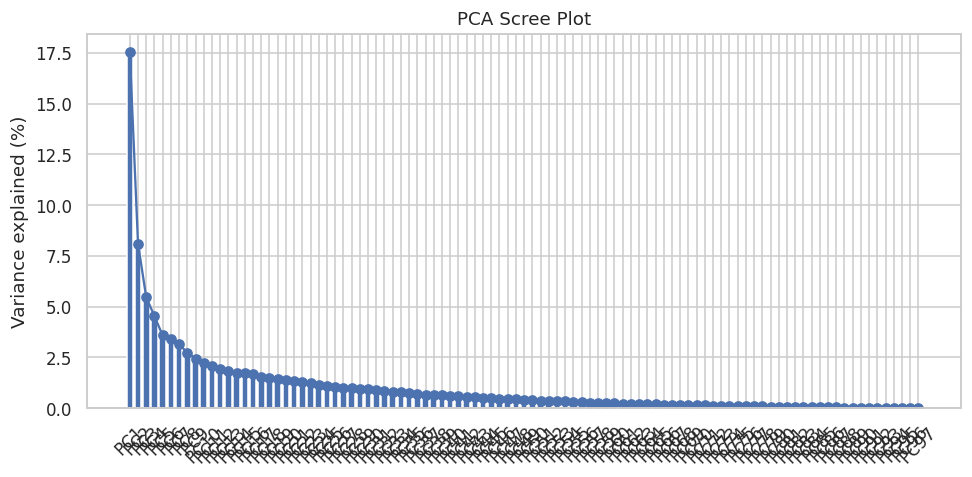

,PC1,PC2
0,1.663960,-1.424260
1,-0.850814,0.499772
2,-0.089057,0.556113
3,6.048543,-3.412369
4,1.046465,-1.450748
5,-1.254463,-0.832991


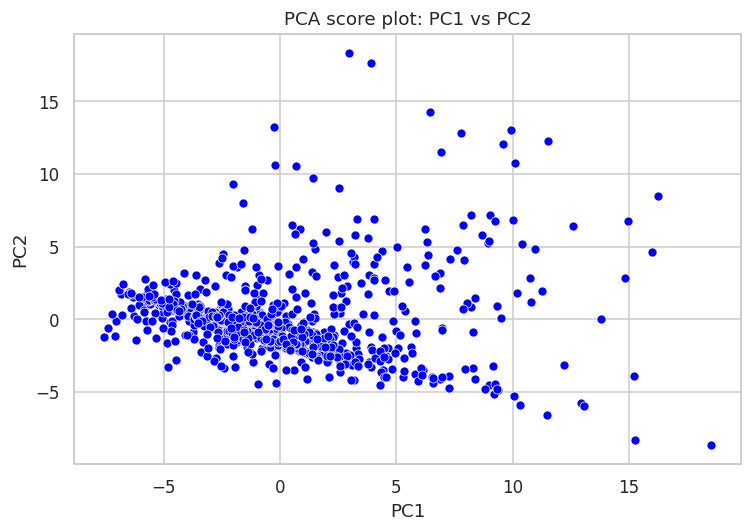

In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

num_cols = df.select_dtypes(include=np.number).columns.tolist()
# Remove constant columns because they do not contribute to PCA.
pca_data = df[num_cols].replace([np.inf, -np.inf], np.nan).dropna()
pca_cols = [c for c in num_cols if pca_data[c].nunique() > 1]
pca_data = pca_data[pca_cols]

if len(pca_cols) >= 2 and len(pca_data) >= 3:
    scaler = StandardScaler()
    data_scaled = scaler.fit_transform(pca_data)
    pca = PCA()
    pca_all = pca.fit_transform(data_scaled)
    explained = pca.explained_variance_ratio_ * 100
    pca_summary = pd.DataFrame({
        "Principal Component": [f"PC{i+1}" for i in range(len(explained))],
        "Variance Explained (%)": explained,
        "Cumulative Variance (%)": np.cumsum(explained)
    })
    display(pca_summary.round(3))

    plt.figure(figsize=(9, 4.5))
    plt.bar(pca_summary["Principal Component"], pca_summary["Variance Explained (%)"])
    plt.plot(pca_summary["Principal Component"], pca_summary["Variance Explained (%)"], marker="o")
    plt.ylabel("Variance explained (%)")
    plt.title("PCA Scree Plot")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

    pca_scores = pd.DataFrame(pca_all[:, :2], columns=["PC1", "PC2"], index=pca_data.index)
    display(pca_scores.head(6))
    plt.figure(figsize=(7, 5))
    sns.scatterplot(data=pca_scores, x="PC1", y="PC2", color="blue", s=35)
    plt.title("PCA score plot: PC1 vs PC2")
    plt.tight_layout()
    plt.show()
else:
    print("PCA skipped: at least two non-constant numeric columns and three complete rows are required.")

16. Clustering — K-Means and hierarchical clustering

K-Means cluster counts (k=2):


,count
0,626
1,197


Cluster centers (standardized feature space):


,rownames,PID,Age,BMI,N.prev.preg,N.living.kids,Tx.time,N.extractions,N.perm.restorations,N.qualifying.teeth,...,BL..FN,BL..S7,V5..AA,V5..PG,V5..TD,V5..TF,V5..PI,V5..CR,V5..FN,V5..S7
0,0.014712,0.027759,-0.081360,-0.064056,-0.033251,-0.039746,-0.081434,-0.024352,-0.044771,-0.243520,...,0.054137,-0.082878,-0.024597,-0.191459,-0.120800,-0.128325,-0.155124,-0.072154,0.048123,-0.136477
1,-0.046749,-0.088210,0.258533,0.203549,0.105660,0.126298,0.258769,0.077384,0.142266,0.773826,...,-0.172030,0.263359,0.078163,0.608391,0.383862,0.407773,0.492932,0.229280,-0.152918,0.433678


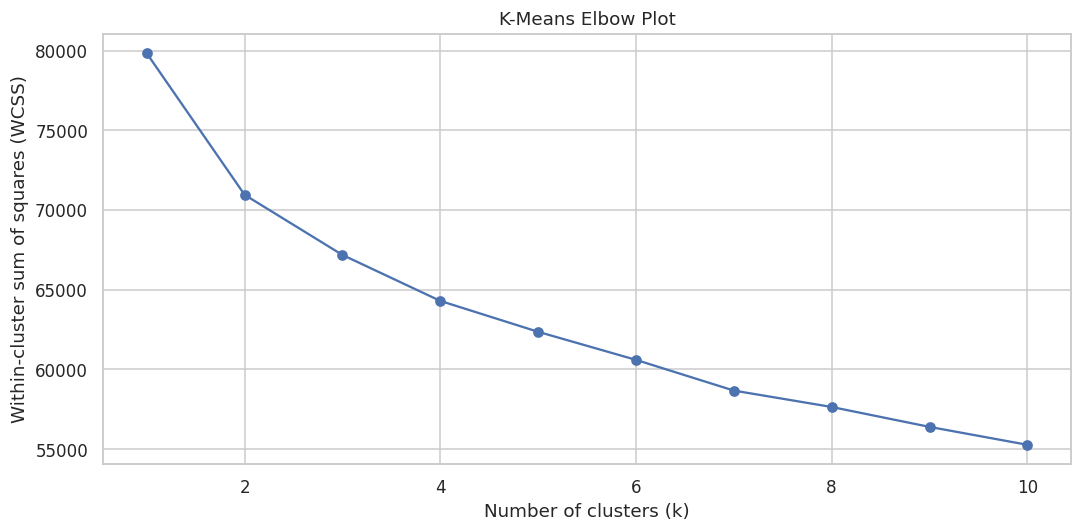

Silhouette score for k=2: 0.2191


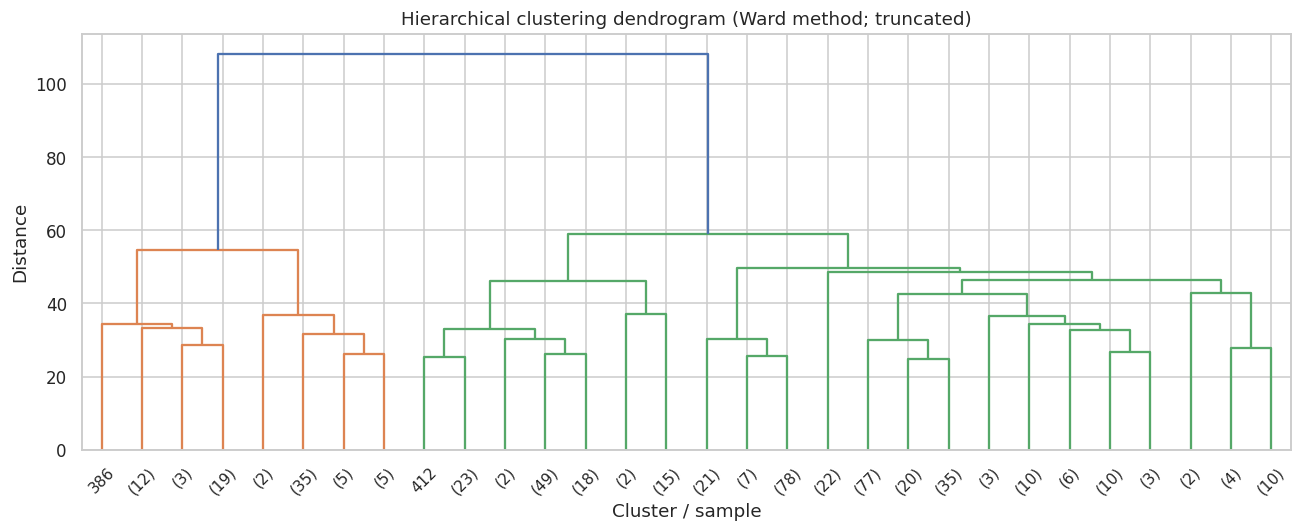

Hierarchical cluster counts (3 clusters):


,count
0,82
1,308
2,110


In [ ]:
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score
from scipy.cluster.hierarchy import linkage, dendrogram

num_cols = df.select_dtypes(include=np.number).columns.tolist()
cluster_data = df[num_cols].replace([np.inf, -np.inf], np.nan).dropna()
cluster_cols = [c for c in num_cols if cluster_data[c].nunique() > 1]
cluster_data = cluster_data[cluster_cols]

# Sampling protects Colab runtime for very large datasets.
if len(cluster_data) > 3000:
    cluster_data = cluster_data.sample(3000, random_state=42)

if len(cluster_cols) >= 2 and len(cluster_data) >= 4:
    X_scaled = StandardScaler().fit_transform(cluster_data)

    # K-means with k=2
    kmeans2 = KMeans(n_clusters=2, random_state=42, n_init=10)
    cluster_labels = kmeans2.fit_predict(X_scaled)
    print("K-Means cluster counts (k=2):")
    display(pd.Series(cluster_labels).value_counts().sort_index().rename("count"))
    print("Cluster centers (standardized feature space):")
    display(pd.DataFrame(kmeans2.cluster_centers_, columns=cluster_cols))

    # Elbow method: WCSS / inertia for k=1..10
    max_k = min(10, len(cluster_data)-1)
    inertias = []
    for k in range(1, max_k+1):
        km = KMeans(n_clusters=k, random_state=42, n_init=10)
        km.fit(X_scaled)
        inertias.append(km.inertia_)
    plt.plot(range(1, max_k+1), inertias, marker="o")
    plt.xlabel("Number of clusters (k)")
    plt.ylabel("Within-cluster sum of squares (WCSS)")
    plt.title("K-Means Elbow Plot")
    plt.tight_layout()
    plt.show()

    if len(set(cluster_labels)) > 1:
        print("Silhouette score for k=2:", round(silhouette_score(X_scaled, cluster_labels), 4))

    # Hierarchical clustering and dendrogram on a small sample
    hier_n = min(500, len(cluster_data))
    X_hier = X_scaled[:hier_n]
    if hier_n >= 4:
        Z = linkage(X_hier, method="ward")
        plt.figure(figsize=(12, 5))
        dendrogram(Z, truncate_mode="lastp", p=30)
        plt.title("Hierarchical clustering dendrogram (Ward method; truncated)")
        plt.xlabel("Cluster / sample")
        plt.ylabel("Distance")
        plt.tight_layout()
        plt.show()

        hier_labels = AgglomerativeClustering(n_clusters=3, linkage="ward").fit_predict(X_hier)
        print("Hierarchical cluster counts (3 clusters):")
        display(pd.Series(hier_labels).value_counts().sort_index().rename("count"))
else:
    print("Clustering skipped: not enough non-constant numeric features or rows.")

17. Optional predictive modelling (only when a suitable categorical target exists)

Automatically selected target: ETXU_CAT5
Target distribution:


,count
ETXU_CAT5,
1,376
.,189
3,107
2,81
5,36
4,34



 Logistic Regression
              precision    recall  f1-score   support

           .       1.00      0.98      0.99        47
           1       0.67      0.52      0.59        94
           2       0.13      0.20      0.16        20
           3       0.41      0.44      0.43        27
           4       0.12      0.22      0.16         9
           5       0.17      0.22      0.19         9

    accuracy                           0.56       206
   macro avg       0.42      0.43      0.42       206
weighted avg       0.61      0.56      0.58       206

Confusion matrix:
 [[46  0  0  1  0  0]
 [ 0 49 20  8 10  7]
 [ 0 12  4  2  1  1]
 [ 0  8  3 12  3  1]
 [ 0  2  0  4  2  1]
 [ 0  2  3  2  0  2]]

 Random Forest
              precision    recall  f1-score   support

           .       1.00      1.00      1.00        47
           1       0.62      0.99      0.77        94
           2       0.00      0.00      0.00        20
           3       0.60      0.22      0.32        27
  

,Model,Accuracy
2,Gradient Boosting,0.718447
1,Random Forest,0.708738
0,Logistic Regression,0.558252


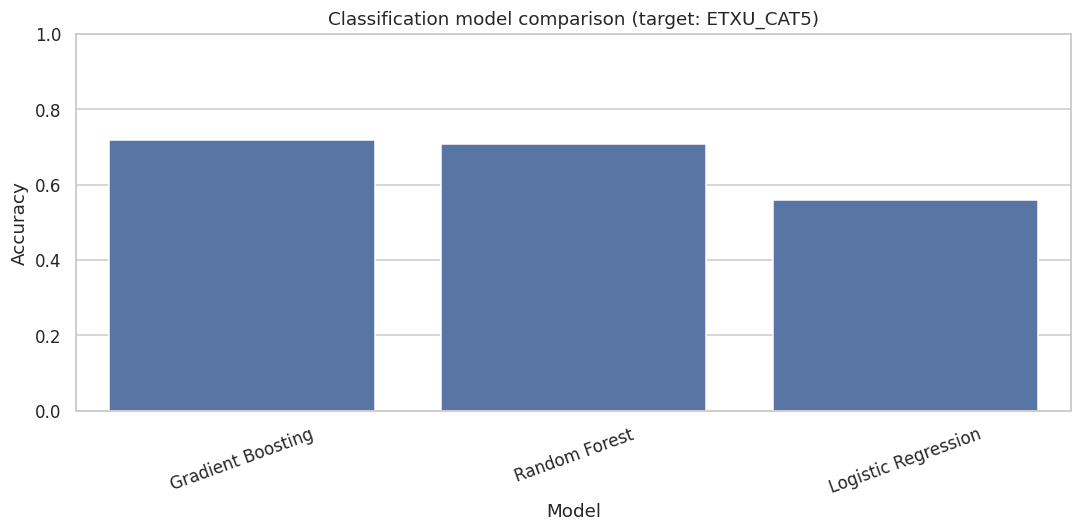

In [ ]:
# Automatically select a categorical target with 2–10 classes and at least 2 observations per class.
# This is a generic fallback; for a meaningful model, replace TARGET with the column you are asked to predict.
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, roc_auc_score
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

possible_targets = [
    c for c in df.select_dtypes(include=["object", "category", "bool"]).columns
    if 2 <= df[c].nunique() <= 10 and df[c].value_counts().min() >= 2
]

if possible_targets:
    TARGET = possible_targets[-1]
    print("Automatically selected target:", TARGET)
    print("Target distribution:")
    display(df[TARGET].value_counts())

    X = df.drop(columns=[TARGET]).copy()
    y = df[TARGET].astype(str).copy()

    # Exclude very high-cardinality text columns and ID-like columns from predictors.
    drop_predictors = []
    for c in X.columns:
        if X[c].dtype == "object" and X[c].nunique() > min(50, 0.5 * len(X)):
            drop_predictors.append(c)
        elif X[c].nunique(dropna=True) >= 0.98 * len(X):
            drop_predictors.append(c)
    X = X.drop(columns=drop_predictors, errors="ignore")

    numeric_features = X.select_dtypes(include=np.number).columns.tolist()
    categorical_features = X.select_dtypes(include=["object", "category", "bool"]).columns.tolist()

    if len(y.unique()) >= 2 and len(X.columns) > 0:
        stratify_arg = y if y.value_counts().min() >= 2 else None
        X_train, X_test, y_train, y_test = train_test_split(
            X, y, test_size=0.25, random_state=42, stratify=stratify_arg
        )

        numeric_transformer = Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler())
        ])
        categorical_transformer = Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(handle_unknown="ignore"))
        ])
        preprocessor = ColumnTransformer([
            ("num", numeric_transformer, numeric_features),
            ("cat", categorical_transformer, categorical_features)
        ])

        models = {
            "Logistic Regression": LogisticRegression(max_iter=1500, class_weight="balanced"),
            "Random Forest": RandomForestClassifier(n_estimators=150, random_state=42, class_weight="balanced"),
            "Gradient Boosting": GradientBoostingClassifier(random_state=42)
        }

        results = []
        for name, model in models.items():
            pipe = Pipeline([("preprocessor", preprocessor), ("model", model)])
            pipe.fit(X_train, y_train)
            pred = pipe.predict(X_test)
            results.append({
                "Model": name,
                "Accuracy": accuracy_score(y_test, pred)
            })
            print("\n", name)
            print(classification_report(y_test, pred, zero_division=0))
            print("Confusion matrix:\n", confusion_matrix(y_test, pred))
        results_df = pd.DataFrame(results).sort_values("Accuracy", ascending=False)
        display(results_df)
        sns.barplot(data=results_df, x="Model", y="Accuracy")
        plt.ylim(0, 1)
        plt.title(f"Classification model comparison (target: {TARGET})")
        plt.xticks(rotation=20)
        plt.tight_layout()
        plt.show()
    else:
        print("Predictive modelling skipped: unsuitable target or predictor matrix.")
else:
    print("No suitable low-cardinality categorical target found. Predictive modelling was skipped.")
    print("Choose a meaningful target column manually if your assignment requires prediction.")

18. Automatic key findings and final summary

In [ ]:
print("FINAL DATASET SUMMARY")
print("-" * 55)
print(f"Rows: {df.shape[0]:,}")
print(f"Columns: {df.shape[1]:,}")
print(f"Numeric columns ({len(df.select_dtypes(include=np.number).columns)}):",
      df.select_dtypes(include=np.number).columns.tolist())
print(f"Categorical columns ({len(df.select_dtypes(include=['object','category','bool']).columns)}):",
      df.select_dtypes(include=["object","category","bool"]).columns.tolist())
print("Missing cells after cleaning:", int(df.isna().sum().sum()))
print("Duplicate rows after cleaning:", int(df.duplicated().sum()))

num_cols = df.select_dtypes(include=np.number).columns.tolist()
if num_cols:
    print("\nNumeric columns with highest standard deviation:")
    display(df[num_cols].std().sort_values(ascending=False).head(5).to_frame("standard_deviation"))
    print("\nStrongest absolute correlations among numeric features (excluding self-correlations):")
    if len(num_cols) >= 2:
        corr = df[num_cols].corr().abs()
        upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool)).stack().sort_values(ascending=False)
        display(upper.head(10).to_frame("absolute_correlation"))

print("\nUse the tables and plots above to write dataset-specific observations.")
print("Do not copy conclusions from the Benefits dataset; your dataset is opt.csv.")

FINAL DATASET SUMMARY
-------------------------------------------------------
Rows: 823
Columns: 169
Numeric columns (97): ['rownames', 'PID', 'Age', 'BMI', 'N.prev.preg', 'N.living.kids', 'Tx.time', 'N.extractions', 'N.perm.restorations', 'N.qualifying.teeth', 'BL.GE', 'BL..BOP', 'BL.PD.avg', 'BL..PD.4', 'BL..PD.5', 'BL.CAL.avg', 'BL..CAL.2', 'BL..CAL.3', 'BL.Calc.I', 'BL.Pl.I', 'V3.GE', 'V3..BOP', 'V3.PD.avg', 'V3..PD.4', 'V3..PD.5', 'V3.CAL.avg', 'V3..CAL.2', 'V3..CAL.3', 'V3.Calc.I', 'V3.Pl.I', 'V5.GE', 'V5..BOP', 'V5.PD.avg', 'V5..PD.4', 'V5..PD.5', 'V5.CAL.avg', 'V5..CAL.2', 'V5..CAL.3', 'V5.Calc.I', 'V5.Pl.I', 'N.PAL.sites', 'GA.at.outcome', 'Birthweight', 'Apgar1', 'Apgar5', 'GA...1st.SAE', 'BL.Anti.inf', 'BL.Cortico', 'BL.Antibio', 'BL.Bac.vag', 'V3.Anti.inf', 'V3.Cortico', 'V3.Antibio', 'V3.Bac.vag', 'V5.Anti.inf', 'V5.Cortico', 'V5.Antibio', 'V5.Bac.vag', 'X..Vis.Att', 'X..Vis.Elig', 'X1st.Miss.Vis', 'BL.DNA', 'BL.Univ', 'BL.AA', 'BL.PG', 'BL.TD', 'BL.TF', 'BL.PI', 'BL.CR', 

,standard_deviation
BL.Univ,9.844387e+07
V5.Univ,7.825860e+07
BL.S7,3.185642e+07
V5.S7,2.417667e+07
BL.FN,1.315485e+07



Strongest absolute correlations among numeric features (excluding self-correlations):


,,absolute_correlation
V3.CAL.avg,V3..CAL.2,0.968651
rownames,PID,0.967818
V5.CAL.avg,V5..CAL.2,0.961176
V5.PD.avg,V5..PD.4,0.958299
V3.PD.avg,V3..PD.4,0.956964
BL.PD.avg,BL..PD.4,0.954975
BL.CAL.avg,BL..CAL.2,0.949823
V3.Calc.I,V5.Calc.I,0.925016
BL.PD.avg,BL..PD.5,0.922970
BL.CAL.avg,BL..CAL.3,0.914981



Use the tables and plots above to write dataset-specific observations.
Do not copy conclusions from the Benefits dataset; your dataset is opt.csv.
